<a href="https://colab.research.google.com/github/Miro-09/DEPI-R5-Professional-Data-Analyst-project/blob/main/Colab%20python%20notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Hosppital Patient Records — Explore Data + Relational Database

## 1. Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3


## 2. Load Data (upload the 5 CSV files)

In [3]:
# Google Drive input setup. Original project loading cells remain unchanged.
from google.colab import auth
auth.authenticate_user()

from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from pathlib import Path
import io

DRIVE_FOLDER_ID = "1IHSjX9snyeXlslA2PpRgcbIXa6U992It"
REQUIRED_FILES = {"patients.csv", "encounters.csv", "procedures.csv", "payers.csv", "organizations.csv"}
DOWNLOAD_DIR = Path("/content")
drive_service = build("drive", "v3")

def download_required_csvs(folder_id):
    found = set()
    folders_to_scan = [folder_id]
    while folders_to_scan:
        current_folder = folders_to_scan.pop()
        page_token = None
        while True:
            response = drive_service.files().list(
                q=f"'{current_folder}' in parents and trashed = false",
                fields="nextPageToken, files(id, name, mimeType)",
                pageSize=1000,
                pageToken=page_token
            ).execute()
            for item in response.get("files", []):
                if item["mimeType"] == "application/vnd.google-apps.folder":
                    folders_to_scan.append(item["id"])
                elif item["name"].lower() in REQUIRED_FILES:
                    request = drive_service.files().get_media(fileId=item["id"])
                    destination = DOWNLOAD_DIR / item["name"].lower()
                    with open(destination, "wb") as output_file:
                        downloader = MediaIoBaseDownload(output_file, request)
                        done = False
                        while not done:
                            _, done = downloader.next_chunk()
                    found.add(item["name"].lower())
                    print(f"Downloaded: {item['name']}")
            page_token = response.get("nextPageToken")
            if not page_token:
                break
    missing = REQUIRED_FILES - found
    if missing:
        raise FileNotFoundError(
            "The following required CSV files were not found in the selected Drive folder: "
            + ", ".join(sorted(missing))
        )

download_required_csvs(DRIVE_FOLDER_ID)
print("All five raw CSV files are ready in /content. Continue with the original notebook.")


Downloaded: procedures.csv
Downloaded: payers.csv
Downloaded: patients.csv
Downloaded: organizations.csv
Downloaded: encounters.csv
All five raw CSV files are ready in /content. Continue with the original notebook.


In [4]:
# Data loading: read the CSV files directly from the Colab session storage (/content)
DATA_PATH = ""   # change this only if the files are inside a sub-folder

patients      = pd.read_csv(DATA_PATH + "patients.csv",      encoding="utf-8-sig")
encounters    = pd.read_csv(DATA_PATH + "encounters.csv",    encoding="utf-8-sig")
procedures    = pd.read_csv(DATA_PATH + "procedures.csv",    encoding="utf-8-sig")
payers        = pd.read_csv(DATA_PATH + "payers.csv",        encoding="utf-8-sig")
organizations = pd.read_csv(DATA_PATH + "organizations.csv", encoding="utf-8-sig")

## 3. Explore Data

### Patients

In [5]:
patients.head()

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
0,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1977-03-19,NaN,Mrs.,Nikita578,Erdman779,NaN,Leannon79,M,white,nonhispanic,F,Wakefield Massachusetts US,510 Little Station Unit 69,Quincy,Massachusetts,Norfolk County,2186.0,42.290937,-70.975503
1,6e5ae27c-8038-7988-e2c0-25a103f01bfa,1940-02-19,NaN,Mr.,Zane918,Hodkiewicz467,NaN,NaN,M,white,nonhispanic,M,Brookline Massachusetts US,747 Conn Throughway,Boston,Massachusetts,Suffolk County,2135.0,42.308831,-71.063162
2,8123d076-0886-9007-e956-d5864aa121a7,1958-06-04,NaN,Mr.,Quinn173,Marquardt819,NaN,NaN,M,white,nonhispanic,M,Gardner Massachusetts US,816 Okuneva Extension Apt 91,Quincy,Massachusetts,Norfolk County,2170.0,42.265177,-70.967085
3,770518e4-6133-648e-60c9-071eb2f0e2ce,1928-12-25,2017-09-29,Mr.,Abel832,Smitham825,NaN,NaN,M,white,hispanic,M,Randolph Massachusetts US,127 Cole Way Unit 95,Boston,Massachusetts,Suffolk County,2118.0,42.334304,-71.066801
4,f96addf5-81b9-0aab-7855-d208d3d352c5,1928-12-25,2014-02-23,Mr.,Edwin773,Labadie908,NaN,NaN,M,white,hispanic,M,Stow Massachusetts US,976 Ziemann Gateway,Boston,Massachusetts,Suffolk County,2125.0,42.346771,-71.058813


In [6]:
patients.shape

(974, 20)

In [7]:
patients.isnull().sum()

,0
Id,0
BIRTHDATE,0
DEATHDATE,820
PREFIX,0
FIRST,0
LAST,0
SUFFIX,953
MAIDEN,588
MARITAL,1
RACE,0


In [8]:
patients.duplicated().sum()

np.int64(0)

In [9]:
patients['GENDER'].value_counts()

,count
GENDER,
M,494
F,480


### Encounters

In [10]:
encounters.head()

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02T09:26:36Z,2011-01-02T12:58:36Z,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,1018.02,0.00,NaN,NaN
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03T05:44:39Z,2011-01-03T06:01:42Z,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,2619.36,0.00,NaN,NaN
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03T14:32:11Z,2011-01-03T14:47:11Z,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,NaN,NaN
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03T16:24:45Z,2011-01-03T16:39:45Z,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,1784.24,0.00,NaN,NaN
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03T17:36:53Z,2011-01-03T17:51:53Z,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,55822004.0,Hyperlipidemia


In [11]:
encounters.shape

(27891, 14)

In [12]:
encounters.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27891 entries, 0 to 27890
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   27891 non-null  object 
 1   START                27891 non-null  object 
 2   STOP                 27891 non-null  object 
 3   PATIENT              27891 non-null  object 
 4   ORGANIZATION         27891 non-null  object 
 5   PAYER                27891 non-null  object 
 6   ENCOUNTERCLASS       27891 non-null  object 
 7   CODE                 27891 non-null  int64  
 8   DESCRIPTION          27891 non-null  object 
 9   BASE_ENCOUNTER_COST  27891 non-null  float64
 10  TOTAL_CLAIM_COST     27891 non-null  float64
 11  PAYER_COVERAGE       27891 non-null  float64
 12  REASONCODE           8350 non-null   float64
 13  REASONDESCRIPTION    8350 non-null   object 
dtypes: float64(4), int64(1), object(9)
memory usage: 3.0+ MB


In [13]:
encounters.describe()

,CODE,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE
count,2.789100e+04,27891.000000,27891.000000,27891.000000,8.350000e+03
mean,2.972670e+08,116.181614,3639.682174,1114.965652,4.751643e+11
std,2.017839e+08,28.410082,9205.595748,4768.615576,5.874089e+12
min,1.505002e+06,85.550000,0.000000,0.000000,5.602001e+06
25%,1.853450e+08,85.550000,142.580000,0.000000,5.582200e+07
50%,1.853490e+08,136.800000,278.580000,28.440000,8.880501e+07
75%,4.244410e+08,142.580000,1412.530000,155.770000,1.956620e+08
max,7.029270e+08,146.180000,641882.700000,247751.420000,1.241710e+14


In [14]:
encounters.isnull().sum()

,0
Id,0
START,0
STOP,0
PATIENT,0
ORGANIZATION,0
PAYER,0
ENCOUNTERCLASS,0
CODE,0
DESCRIPTION,0
BASE_ENCOUNTER_COST,0


In [15]:
encounters.duplicated().sum()

np.int64(0)

In [16]:
encounters['ENCOUNTERCLASS'].value_counts()

,count
ENCOUNTERCLASS,
ambulatory,12537
outpatient,6300
urgentcare,3666
emergency,2322
wellness,1931
inpatient,1135


### Procedures

In [17]:
procedures.head()

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,REASONCODE,REASONDESCRIPTION
0,2011-01-02T09:26:36Z,2011-01-02T12:58:36Z,3de74169-7f67-9304-91d4-757e0f3a14d2,32c84703-2481-49cd-d571-3899d5820253,265764009,Renal dialysis (procedure),903,NaN,NaN
1,2011-01-03T05:44:39Z,2011-01-03T06:01:42Z,d9ec2e44-32e9-9148-179a-1653348cc4e2,c98059da-320a-c0a6-fced-c8815f3e3f39,76601001,Intramuscular injection,2477,NaN,NaN
2,2011-01-04T14:49:55Z,2011-01-04T15:04:55Z,d856d6e6-4c98-e7a2-129b-44076c63d008,2cfd4ddd-ad13-fe1e-528b-15051cea2ec3,703423002,Combined chemotherapy and radiation therapy (p...,11620,363406005.0,Malignant tumor of colon
3,2011-01-05T04:02:09Z,2011-01-05T04:17:09Z,bc9d59c3-0a30-6e3b-f47d-022e4f03c8de,17966936-0878-f4db-128b-a43ae10d0878,173160006,Diagnostic fiberoptic bronchoscopy (procedure),9796,162573006.0,Suspected lung cancer (situation)
4,2011-01-05T12:58:36Z,2011-01-05T16:42:36Z,3de74169-7f67-9304-91d4-757e0f3a14d2,9de5f0b0-4ba4-ce6f-45fb-b55c202f31a5,265764009,Renal dialysis (procedure),1255,NaN,NaN


In [18]:
procedures.shape

(47701, 9)

In [19]:
procedures.isnull().sum()

,0
START,0
STOP,0
PATIENT,0
ENCOUNTER,0
CODE,0
DESCRIPTION,0
BASE_COST,0
REASONCODE,36945
REASONDESCRIPTION,36945


In [20]:
procedures.duplicated().sum()

np.int64(0)

### Payers & Organizations

In [21]:
payers

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323
1,7caa7254-5050-3b5e-9eae-bd5ea30e809c,Medicare,7500 Security Blvd,Baltimore,MD,21244.0,1-800-633-4227
2,7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,Medicaid,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323
3,d47b3510-2895-3b70-9897-342d681c769d,Humana,500 West Main St,Louisville,KY,40018.0,1-844-330-7799
4,6e2f1a2d-27bd-3701-8d08-dae202c58632,Blue Cross Blue Shield,Michigan Plaza,Chicago,IL,60007.0,1-800-262-2583
5,5059a55e-5d6e-34d1-b6cb-d83d16e57bcf,UnitedHealthcare,9800 Healthcare Lane,Minnetonka,MN,55436.0,1-888-545-5205
6,4d71f845-a6a9-3c39-b242-14d25ef86a8d,Aetna,151 Farmington Ave,Hartford,CT,6156.0,1-800-872-3862
7,047f6ec3-6215-35eb-9608-f9dda363a44c,Cigna Health,900 Cottage Grove Rd,Bloomfield,CT,6002.0,1-800-997-1654
8,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,Anthem,220 Virginia Ave,Indianapolis,IN,46204.0,1-800-331-1476
9,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,NO_INSURANCE,NaN,NaN,NaN,NaN,NaN


In [22]:
organizations

,Id,NAME,ADDRESS,CITY,STATE,ZIP,LAT,LON
0,d78e84ec-30aa-3bba-a33a-f29a3a454662,MASSACHUSETTS GENERAL HOSPITAL,55 FRUIT STREET,BOSTON,MA,2114,42.362813,-71.069187


### Charts

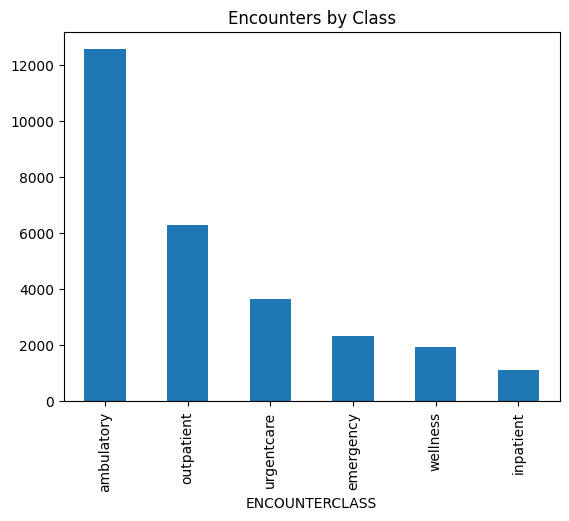

In [23]:
encounters['ENCOUNTERCLASS'].value_counts().plot(kind='bar', title='Encounters by Class');

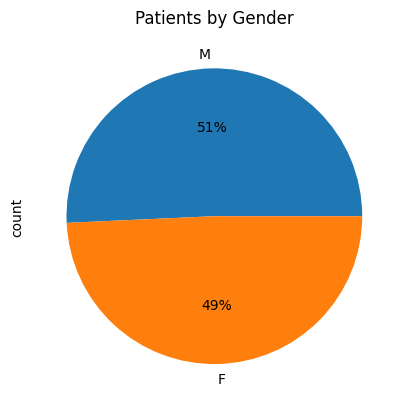

In [24]:
patients['GENDER'].value_counts().plot(kind='pie', autopct='%1.0f%%', title='Patients by Gender');

In [25]:
# Preprocessing setup and raw data preservation

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

def tables():
    return {
        "patients": patients,
        "encounters": encounters,
        "procedures": procedures,
        "payers": payers,
        "organizations": organizations
    }

# Preserve the original datasets
raw_tables = {
    name: df.copy(deep=True)
    for name, df in tables().items()
}

# Create the initial data quality summary
raw_summary = pd.DataFrame({
    "rows": {
        name: len(df)
        for name, df in raw_tables.items()
    },
    "columns": {
        name: df.shape[1]
        for name, df in raw_tables.items()
    },
    "missing_cells": {
        name: int(df.isna().sum().sum())
        for name, df in raw_tables.items()
    },
    "exact_duplicates": {
        name: int(df.duplicated().sum())
        for name, df in raw_tables.items()
    }
})

display(raw_summary)

,rows,columns,missing_cells,exact_duplicates
patients,974,20,2504,0
encounters,27891,14,39082,0
procedures,47701,9,73890,0
payers,10,7,5,0
organizations,1,8,0,0


In [26]:
# Data type conversion and validation

def to_naive_datetime(series):

    return (
        pd.to_datetime(
            series,
            utc=True,
            errors="coerce"
        )
        .dt.tz_localize(None)
    )


def to_text_code(series, width=None):

    cleaned = (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

    cleaned = cleaned.replace("", pd.NA)

    if width is not None:
        cleaned = cleaned.str.zfill(width)

    return cleaned


# Convert patient dates
patients["BIRTHDATE"] = to_naive_datetime(
    patients["BIRTHDATE"]
)

patients["DEATHDATE"] = to_naive_datetime(
    patients["DEATHDATE"]
)


# Convert encounter and procedure dates
for df in [encounters, procedures]:

    df["START"] = to_naive_datetime(df["START"])
    df["STOP"] = to_naive_datetime(df["STOP"])

    df["CODE"] = to_text_code(df["CODE"])
    df["REASONCODE"] = to_text_code(df["REASONCODE"])


# Preserve postal codes as identifiers
patients["ZIP"] = to_text_code(patients["ZIP"], 5)
payers["ZIP"] = to_text_code(payers["ZIP"], 5)
organizations["ZIP"] = to_text_code(
    organizations["ZIP"], 5
)


# Convert financial columns
financial_columns = {
    "encounters": [
        "BASE_ENCOUNTER_COST",
        "TOTAL_CLAIM_COST",
        "PAYER_COVERAGE"
    ],
    "procedures": [
        "BASE_COST"
    ]
}

for name, columns in financial_columns.items():

    df = tables()[name]

    for col in columns:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )


# Convert geographic coordinates
for df in [patients, organizations]:

    for col in ["LAT", "LON"]:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )


# Detect values that failed conversion
conversion_errors = []

date_columns = {
    "patients": ["BIRTHDATE", "DEATHDATE"],
    "encounters": ["START", "STOP"],
    "procedures": ["START", "STOP"]
}

numeric_columns = {
    **financial_columns,
    "patients": ["LAT", "LON"],
    "organizations": ["LAT", "LON"]
}

for name, columns in {
    **date_columns,
    **{
        key: date_columns.get(key, []) + numeric_columns.get(key, [])
        for key in numeric_columns
    }
}.items():

    for col in columns:

        raw = raw_tables[name][col]
        clean = tables()[name][col]

        conversion_errors.append({
            "Dataset": name,
            "Column": col,
            "Conversion_Errors": int(
                (raw.notna() & clean.isna()).sum()
            )
        })

conversion_report = pd.DataFrame(conversion_errors)

display(conversion_report)

assert conversion_report["Conversion_Errors"].sum() == 0, (
    "Data conversion errors detected. Review the report."
)

,Dataset,Column,Conversion_Errors
0,patients,BIRTHDATE,0
1,patients,DEATHDATE,0
2,patients,LAT,0
3,patients,LON,0
4,encounters,START,0
5,encounters,STOP,0
6,encounters,BASE_ENCOUNTER_COST,0
7,encounters,TOTAL_CLAIM_COST,0
8,encounters,PAYER_COVERAGE,0
9,procedures,START,0


In [27]:
# Text cleaning and standardization

# Remove unnecessary whitespace
for name, df in tables().items():

    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for col in text_columns:

        df[col] = (
            df[col]
            .astype("string")
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
        )

        df[col] = df[col].replace(
            r"^\s*$",
            pd.NA,
            regex=True
        )


# Standardize geographic names
for df in [patients, payers, organizations]:

    for col in ["CITY", "STATE", "COUNTY"]:

        if col in df.columns:

            df[col] = df[col].str.title()


# Standardize organization names
if "NAME" in organizations.columns:

    organizations["NAME"] = (
        organizations["NAME"].str.strip()
    )


# Standardize payer names
if "NAME" in payers.columns:

    payers["NAME"] = payers["NAME"].replace({
        "NO_INSURANCE": "No Insurance"
    })


# Preserve original patient names
for col in ["FIRST", "LAST", "PREFIX", "SUFFIX"]:

    if col in patients.columns:

        patients[col] = patients[col].str.strip()


# Clean medical descriptions
for df in [encounters, procedures]:

    for col in ["DESCRIPTION", "REASONDESCRIPTION"]:

        if col in df.columns:

            df[col] = (
                df[col]
                .astype("string")
                .str.strip()
            )


print("Text cleaning completed successfully.")

Text cleaning completed successfully.


In [28]:
# Categorical standardization and validation

category_maps = {
    "GENDER": {
        "M": "Male",
        "F": "Female",
        "Male": "Male",
        "Female": "Female"
    },

    "MARITAL": {
        "M": "Married",
        "S": "Single",
        "Married": "Married",
        "Single": "Single",
        "Unknown": "Unknown"
    },

    "ETHNICITY": {
        "hispanic": "Hispanic",
        "nonhispanic": "Non-Hispanic",
        "Hispanic": "Hispanic",
        "Non-Hispanic": "Non-Hispanic"
    }
}

category_validation = []

for col, mapping in category_maps.items():

    original = patients[col].copy()

    unexpected_values = sorted(
        set(original.dropna().unique()) - set(mapping.keys())
    )

    category_validation.append({
        "Column": col,
        "Unexpected_Values": unexpected_values,
        "Unexpected_Count": int(
            original.isin(unexpected_values).sum()
        )
    })

    if unexpected_values:
        raise ValueError(
            f"Unexpected categories in {col}: {unexpected_values}"
        )

    patients[col] = original.map(mapping).astype("string")


# Standardize race names
patients["RACE"] = (
    patients["RACE"]
    .astype("string")
    .str.strip()
    .str.title()
)


# Standardize encounter classes
class_map = {
    "ambulatory": "Ambulatory",
    "emergency": "Emergency",
    "inpatient": "Inpatient",
    "outpatient": "Outpatient",
    "urgentcare": "Urgent Care",
    "wellness": "Wellness",
    "Ambulatory": "Ambulatory",
    "Emergency": "Emergency",
    "Inpatient": "Inpatient",
    "Outpatient": "Outpatient",
    "Urgent Care": "Urgent Care",
    "Wellness": "Wellness"
}

unexpected_classes = (
    set(encounters["ENCOUNTERCLASS"].dropna().unique())
    - set(class_map.keys())
)

if unexpected_classes:
    raise ValueError(
        f"Unexpected encounter classes: {unexpected_classes}"
    )

encounters["ENCOUNTERCLASS"] = (
    encounters["ENCOUNTERCLASS"]
    .map(class_map)
    .astype("string")
)


# Generate categorical validation report
category_validation_report = pd.DataFrame(
    category_validation
)

display(category_validation_report)

display(
    patients[
        ["GENDER", "MARITAL", "RACE", "ETHNICITY"]
    ].describe().T
)

print("Categorical standardization completed successfully.")

,Column,Unexpected_Values,Unexpected_Count
0,GENDER,[],0
1,MARITAL,[],0
2,ETHNICITY,[],0


,count,unique,top,freq
GENDER,974,2,Male,494
MARITAL,973,2,Married,784
RACE,974,6,White,680
ETHNICITY,974,2,Non-Hispanic,783


Categorical standardization completed successfully.


In [29]:
# Missing values (audit): count and percentage of nulls per column before any treatment
def missing_report(df):
    report = pd.DataFrame({"missing": df.isnull().sum(), "pct": (df.isnull().mean() * 100).round(2)})
    return report[report["missing"] > 0]

for name, df in tables().items():
    print(f"--- {name} ---")
    display(missing_report(df))

--- patients ---


,missing,pct
DEATHDATE,820,84.19
SUFFIX,953,97.84
MAIDEN,588,60.37
MARITAL,1,0.10
ZIP,142,14.58


--- encounters ---


,missing,pct
REASONCODE,19541,70.06
REASONDESCRIPTION,19541,70.06


--- procedures ---


,missing,pct
REASONCODE,36945,77.45
REASONDESCRIPTION,36945,77.45


--- payers ---


,missing,pct
ADDRESS,1,10.00
CITY,1,10.00
STATE_HEADQUARTERED,1,10.00
ZIP,1,10.00
PHONE,1,10.00


--- organizations ---


,missing,pct


In [30]:
# Missing values classification and treatment

# Standardize missing categorical values
if "MARITAL" in patients.columns:
    patients["MARITAL"] = (
        patients["MARITAL"]
        .fillna("Unknown")
    )


# Preserve meaningful missing patient attributes
optional_patient_columns = [
    "DEATHDATE",
    "SUFFIX",
    "MAIDEN",
    "ZIP"
]

for col in optional_patient_columns:

    if col in patients.columns:
        patients[col] = patients[col].where(
            patients[col].notna(),
            pd.NA
        )


# Preserve missing medical reasons
for df in [encounters, procedures]:

    for col in ["REASONCODE", "REASONDESCRIPTION"]:

        if col in df.columns:
            df[col] = df[col].where(
                df[col].notna(),
                pd.NA
            )


# Preserve missing payer contact information
optional_payer_columns = [
    "ADDRESS",
    "CITY",
    "STATE_HEADQUARTERED",
    "ZIP",
    "PHONE"
]

for col in optional_payer_columns:

    if col in payers.columns:
        payers[col] = payers[col].where(
            payers[col].notna(),
            pd.NA
        )


# Generate missing values report
missing_after_treatment = []

for name, df in tables().items():

    for col in df.columns:

        missing_count = int(df[col].isna().sum())

        if missing_count > 0:

            missing_after_treatment.append({
                "Dataset": name,
                "Column": col,
                "Missing_Count": missing_count,
                "Missing_Percentage": round(
                    missing_count / len(df) * 100,
                    2
                ) if len(df) > 0 else 0
            })


missing_after_treatment = pd.DataFrame(
    missing_after_treatment,
    columns=[
        "Dataset",
        "Column",
        "Missing_Count",
        "Missing_Percentage"
    ]
)

display(missing_after_treatment)

print("Missing values assessment completed successfully.")

,Dataset,Column,Missing_Count,Missing_Percentage
0,patients,DEATHDATE,820,84.19
1,patients,SUFFIX,953,97.84
2,patients,MAIDEN,588,60.37
3,patients,ZIP,142,14.58
4,encounters,REASONCODE,19541,70.06
5,encounters,REASONDESCRIPTION,19541,70.06
6,procedures,REASONCODE,36945,77.45
7,procedures,REASONDESCRIPTION,36945,77.45
8,payers,ADDRESS,1,10.00
9,payers,CITY,1,10.00


Missing values assessment completed successfully.


In [31]:
# Duplicate detection and safe removal

key_columns = {
    "patients": "Id",
    "encounters": "Id",
    "payers": "Id",
    "organizations": "Id"
}

duplicate_results = []
conflicting_records = {}

for name, df in tables().items():

    exact_duplicates = int(
        df.duplicated().sum()
    )

    if name in key_columns:

        key = key_columns[name]

        missing_keys = int(
            df[key].isna().sum()
        )

        conflicting_mask = df.duplicated(
            subset=[key],
            keep=False
        )

        conflicting_records[name] = df.loc[
            conflicting_mask
        ].copy()

        conflicting_count = int(
            conflicting_mask.sum()
        )

    else:

        missing_keys = None
        conflicting_count = None

    duplicate_results.append({
        "Dataset": name,
        "Exact_Duplicates": exact_duplicates,
        "Missing_Primary_Keys": missing_keys,
        "Rows_With_Duplicate_Keys": conflicting_count
    })


duplicate_audit = pd.DataFrame(
    duplicate_results
)

display(duplicate_audit)


# Stop if primary key conflicts exist
for name, df in conflicting_records.items():

    if not df.empty:

        raise ValueError(
            f"Duplicate primary keys detected in {name}. "
            "Review conflicting records before cleaning."
        )


# Stop if primary keys are missing
for name, key in key_columns.items():

    if tables()[name][key].isna().any():

        raise ValueError(
            f"Missing primary keys detected in {name}."
        )


# Remove exact duplicate rows only
patients = patients.drop_duplicates().reset_index(drop=True)

encounters = encounters.drop_duplicates().reset_index(drop=True)

procedures = procedures.drop_duplicates().reset_index(drop=True)

payers = payers.drop_duplicates().reset_index(drop=True)

organizations = organizations.drop_duplicates().reset_index(drop=True)


print("Exact duplicate removal completed successfully.")

,Dataset,Exact_Duplicates,Missing_Primary_Keys,Rows_With_Duplicate_Keys
0,patients,0,0.00,0.00
1,encounters,0,0.00,0.00
2,procedures,0,NaN,NaN
3,payers,0,0.00,0.00
4,organizations,0,0.00,0.00


Exact duplicate removal completed successfully.


In [32]:
# Referential integrity validation

integrity_checks = {}


# Validate encounter relationships
integrity_checks["Encounter_Patient"] = int(
    (~encounters["PATIENT"].isin(patients["Id"])).sum()
)

integrity_checks["Encounter_Payer"] = int(
    (~encounters["PAYER"].isin(payers["Id"])).sum()
)

integrity_checks["Encounter_Organization"] = int(
    (~encounters["ORGANIZATION"].isin(organizations["Id"])).sum()
)


# Validate procedure relationships
integrity_checks["Procedure_Patient"] = int(
    (~procedures["PATIENT"].isin(patients["Id"])).sum()
)

integrity_checks["Procedure_Encounter"] = int(
    (~procedures["ENCOUNTER"].isin(encounters["Id"])).sum()
)


# Validate procedure-patient consistency
encounter_patient_map = (
    encounters.set_index("Id")["PATIENT"]
)

expected_patient = (
    procedures["ENCOUNTER"]
    .map(encounter_patient_map)
)

patient_mismatch = (
    expected_patient.notna()
    &
    procedures["PATIENT"].ne(
        expected_patient
    ).fillna(False)
)

integrity_checks["Procedure_Patient_Mismatch"] = int(
    patient_mismatch.sum()
)


# Generate integrity report
integrity_report = pd.DataFrame(
    integrity_checks.items(),
    columns=[
        "Validation_Check",
        "Invalid_Records"
    ]
)

display(integrity_report)


# Prevent invalid relationships from passing silently
if integrity_report["Invalid_Records"].sum() > 0:

    raise ValueError(
        "Referential integrity violations detected. "
        "Review invalid records before continuing."
    )

print("All referential integrity checks passed.")

,Validation_Check,Invalid_Records
0,Encounter_Patient,0
1,Encounter_Payer,0
2,Encounter_Organization,0
3,Procedure_Patient,0
4,Procedure_Encounter,0
5,Procedure_Patient_Mismatch,0


All referential integrity checks passed.


In [33]:
# Comprehensive data validation

validation_results = []


def add_check(dataset, check_name, mask, severity="Critical"):

    validation_results.append({
        "Dataset": dataset,
        "Validation_Check": check_name,
        "Severity": severity,
        "Invalid_Records": int(mask.fillna(False).sum())
    })


# Patient date validation
add_check(
    "patients",
    "Missing Birthdate",
    patients["BIRTHDATE"].isna()
)

add_check(
    "patients",
    "Death Before Birth",
    patients["DEATHDATE"] < patients["BIRTHDATE"]
)


# Encounter date validation
add_check(
    "encounters",
    "Missing Encounter Dates",
    encounters[["START", "STOP"]].isna().any(axis=1)
)

add_check(
    "encounters",
    "Encounter End Before Start",
    encounters["STOP"] < encounters["START"]
)


# Procedure date validation
add_check(
    "procedures",
    "Missing Procedure Dates",
    procedures[["START", "STOP"]].isna().any(axis=1)
)

add_check(
    "procedures",
    "Procedure End Before Start",
    procedures["STOP"] < procedures["START"]
)


# Encounter financial validation
encounter_cost_columns = [
    "BASE_ENCOUNTER_COST",
    "TOTAL_CLAIM_COST",
    "PAYER_COVERAGE"
]

add_check(
    "encounters",
    "Missing Financial Values",
    encounters[encounter_cost_columns].isna().any(axis=1)
)

add_check(
    "encounters",
    "Negative Financial Values",
    encounters[encounter_cost_columns].lt(0).any(axis=1)
)

add_check(
    "encounters",
    "Coverage Exceeds Claim",
    encounters["PAYER_COVERAGE"] > encounters["TOTAL_CLAIM_COST"]
)


# Procedure financial validation
add_check(
    "procedures",
    "Missing Procedure Cost",
    procedures["BASE_COST"].isna()
)

add_check(
    "procedures",
    "Negative Procedure Cost",
    procedures["BASE_COST"] < 0
)


# Geographic validation
for name, df in [
    ("patients", patients),
    ("organizations", organizations)
]:

    add_check(
        name,
        "Invalid Latitude",
        df["LAT"].notna() & ~df["LAT"].between(-90, 90)
    )

    add_check(
        name,
        "Invalid Longitude",
        df["LON"].notna() & ~df["LON"].between(-180, 180)
    )


# Generate validation report
validation_report = pd.DataFrame(validation_results)

display(validation_report)


# Stop processing when critical data errors exist
critical_errors = validation_report.loc[
    validation_report["Severity"] == "Critical",
    "Invalid_Records"
].sum()

if critical_errors > 0:

    raise ValueError(
        f"{critical_errors} critical validation violations detected."
    )

print("All critical data validation checks passed.")

,Dataset,Validation_Check,Severity,Invalid_Records
0,patients,Missing Birthdate,Critical,0
1,patients,Death Before Birth,Critical,0
2,encounters,Missing Encounter Dates,Critical,0
3,encounters,Encounter End Before Start,Critical,0
4,procedures,Missing Procedure Dates,Critical,0
5,procedures,Procedure End Before Start,Critical,0
6,encounters,Missing Financial Values,Critical,0
7,encounters,Negative Financial Values,Critical,0
8,encounters,Coverage Exceeds Claim,Critical,0
9,procedures,Missing Procedure Cost,Critical,0


All critical data validation checks passed.


In [34]:
# Patient feature engineering and accurate age calculation

REFERENCE_DATE = encounters["START"].max().normalize()

patients["IS_DECEASED"] = patients["DEATHDATE"].notna()

# Calculate age at death or reference date
age_end_date = patients["DEATHDATE"].fillna(REFERENCE_DATE)

# Identify whether the birthday has occurred
birthday_not_reached = (
    (age_end_date.dt.month < patients["BIRTHDATE"].dt.month)
    |
    (
        (age_end_date.dt.month == patients["BIRTHDATE"].dt.month)
        &
        (age_end_date.dt.day < patients["BIRTHDATE"].dt.day)
    )
)

# Calculate age in completed years
patients["AGE"] = (
    age_end_date.dt.year
    - patients["BIRTHDATE"].dt.year
    - birthday_not_reached.astype("Int64")
).astype("Int64")

# Validate calculated ages
patients["FLAG_INVALID_AGE"] = (
    patients["AGE"].isna()
    |
    (patients["AGE"] < 0)
    |
    (patients["AGE"] > 120)
).fillna(True)

# Create age groups
patients["AGE_GROUP"] = pd.cut(
    patients["AGE"],
    bins=[-1, 17, 34, 49, 64, 79, 200],
    labels=[
        "0-17",
        "18-34",
        "35-49",
        "50-64",
        "65-79",
        "80+"
    ]
).astype("string")

# Create full name
patients["FULL_NAME"] = (
    patients["FIRST"].fillna("")
    + " "
    + patients["LAST"].fillna("")
).str.strip()

# Generate age validation report
age_validation_report = pd.DataFrame({
    "Validation_Check": [
        "Invalid Ages",
        "Missing Ages",
        "Deceased Patients"
    ],
    "Records": [
        int(patients["FLAG_INVALID_AGE"].sum()),
        int(patients["AGE"].isna().sum()),
        int(patients["IS_DECEASED"].sum())
    ]
})

display(age_validation_report)

# Preview engineered patient features
display(
    patients[
        [
            "FULL_NAME",
            "BIRTHDATE",
            "DEATHDATE",
            "IS_DECEASED",
            "AGE",
            "AGE_GROUP"
        ]
    ].head()
)

print("Patient feature engineering completed successfully.")

,Validation_Check,Records
0,Invalid Ages,0
1,Missing Ages,0
2,Deceased Patients,154


,FULL_NAME,BIRTHDATE,DEATHDATE,IS_DECEASED,AGE,AGE_GROUP
0,Nikita578 Erdman779,1977-03-19,NaT,False,44,35-49
1,Zane918 Hodkiewicz467,1940-02-19,NaT,False,81,80+
2,Quinn173 Marquardt819,1958-06-04,NaT,False,63,50-64
3,Abel832 Smitham825,1928-12-25,2017-09-29,True,88,80+
4,Edwin773 Labadie908,1928-12-25,2014-02-23,True,85,80+


Patient feature engineering completed successfully.


In [35]:
# Feature engineering (encounters): time parts, duration, payer info, financial metrics, patient context
encounters["ENCOUNTER_DATE"] = encounters["START"].dt.normalize()
encounters["YEAR"]           = encounters["START"].dt.year
encounters["MONTH"]          = encounters["START"].dt.month
encounters["MONTH_NAME"]     = encounters["START"].dt.month_name()
encounters["DAY_OF_WEEK"]    = encounters["START"].dt.day_name()
encounters["HOUR"]           = encounters["START"].dt.hour
encounters["DURATION_MIN"]   = (encounters["STOP"] - encounters["START"]).dt.total_seconds() / 60

encounters["PAYER_NAME"]     = encounters["PAYER"].map(payers.set_index("Id")["NAME"])
encounters["IS_INSURED"]     = encounters["PAYER_NAME"] != "No Insurance"

encounters["PATIENT_PAYS"]   = (encounters["TOTAL_CLAIM_COST"] - encounters["PAYER_COVERAGE"]).clip(lower=0)
encounters["COVERAGE_RATE"]  = np.where(encounters["TOTAL_CLAIM_COST"] > 0,
                                        encounters["PAYER_COVERAGE"] / encounters["TOTAL_CLAIM_COST"], np.nan)

birth_map = patients.set_index("Id")["BIRTHDATE"]
# Calculate accurate age at encounter

birth_dates = encounters["PATIENT"].map(
    patients.set_index("Id")["BIRTHDATE"]
)

encounter_dates = encounters["START"]

birthday_not_reached = (
    (encounter_dates.dt.month < birth_dates.dt.month)
    |
    (
        (encounter_dates.dt.month == birth_dates.dt.month)
        &
        (encounter_dates.dt.day < birth_dates.dt.day)
    )
)

encounters["AGE_AT_ENCOUNTER"] = (
    encounter_dates.dt.year
    - birth_dates.dt.year
    - birthday_not_reached.astype("Int64")
).astype("Int64")
encounters["PROCEDURE_COUNT"]  = encounters["Id"].map(procedures["ENCOUNTER"].value_counts()).fillna(0).astype(int)

encounters[["ENCOUNTER_DATE", "DAY_OF_WEEK", "DURATION_MIN", "PAYER_NAME", "PATIENT_PAYS",
            "COVERAGE_RATE", "AGE_AT_ENCOUNTER", "PROCEDURE_COUNT"]].head()

,ENCOUNTER_DATE,DAY_OF_WEEK,DURATION_MIN,PAYER_NAME,PATIENT_PAYS,COVERAGE_RATE,AGE_AT_ENCOUNTER,PROCEDURE_COUNT
0,2011-01-02,Sunday,212.00,No Insurance,"1,018.02",0.00,82,1
1,2011-01-03,Monday,17.05,No Insurance,"2,619.36",0.00,46,1
2,2011-01-03,Monday,15.00,Medicare,156.32,0.66,86,0
3,2011-01-03,Monday,15.00,No Insurance,"1,784.24",0.00,87,0
4,2011-01-03,Monday,15.00,Anthem,234.72,0.00,58,0


In [36]:
# Feature engineering (procedures): date parts and duration
procedures["PROCEDURE_DATE"] = procedures["START"].dt.normalize()
procedures["YEAR"]           = procedures["START"].dt.year
procedures["DURATION_MIN"]   = (procedures["STOP"] - procedures["START"]).dt.total_seconds() / 60

procedures[["PROCEDURE_DATE", "YEAR", "DURATION_MIN", "BASE_COST"]].head()

,PROCEDURE_DATE,YEAR,DURATION_MIN,BASE_COST
0,2011-01-02,2011,212.00,903
1,2011-01-03,2011,17.05,2477
2,2011-01-04,2011,15.00,11620
3,2011-01-05,2011,15.00,9796
4,2011-01-05,2011,224.00,1255


In [37]:
# Clinical and temporal consistency validation

birth_map = patients.set_index("Id")["BIRTHDATE"]
death_map = patients.set_index("Id")["DEATHDATE"]

encounter_birth = encounters["PATIENT"].map(birth_map)
encounter_death = encounters["PATIENT"].map(death_map)


# Validate encounter dates against patient history
encounters["FLAG_BEFORE_BIRTH"] = (
    encounters["START"] < encounter_birth
)

encounters["FLAG_AFTER_DEATH"] = (
    encounter_death.notna()
    &
    (encounters["START"] > encounter_death)
)

encounters["FLAG_INVALID_TIME"] = (
    encounters["STOP"] < encounters["START"]
)


# Validate encounter financial logic
encounters["FLAG_ZERO_COST"] = (
    encounters["TOTAL_CLAIM_COST"] == 0
)

encounters["FLAG_NEGATIVE_COST"] = (
    encounters[[
        "BASE_ENCOUNTER_COST",
        "TOTAL_CLAIM_COST",
        "PAYER_COVERAGE"
    ]].lt(0).any(axis=1)
)

encounters["FLAG_COVERAGE_GT_COST"] = (
    encounters["PAYER_COVERAGE"]
    >
    encounters["TOTAL_CLAIM_COST"]
)


# Validate procedure dates and costs
procedures["FLAG_INVALID_TIME"] = (
    procedures["STOP"] < procedures["START"]
)

procedures["FLAG_NEGATIVE_COST"] = (
    procedures["BASE_COST"] < 0
)


# Validate procedure-patient consistency
encounter_patient_map = (
    encounters.set_index("Id")["PATIENT"]
)

procedures["FLAG_PATIENT_MISMATCH"] = (
    procedures["PATIENT"].ne(
        procedures["ENCOUNTER"].map(encounter_patient_map)
    ).fillna(False)
)


# Validate procedure timing against encounter timing
encounter_start_map = encounters.set_index("Id")["START"]
encounter_stop_map = encounters.set_index("Id")["STOP"]

procedures["FLAG_OUTSIDE_ENCOUNTER"] = (
    (
        procedures["START"]
        <
        procedures["ENCOUNTER"].map(encounter_start_map)
    )
    |
    (
        procedures["STOP"]
        >
        procedures["ENCOUNTER"].map(encounter_stop_map)
    )
)


# Generate logical validation report
encounter_flags = [
    col for col in encounters.columns
    if col.startswith("FLAG_")
]

procedure_flags = [
    col for col in procedures.columns
    if col.startswith("FLAG_")
]

logical_validation_report = pd.concat([
    encounters[encounter_flags].sum().rename("Encounters"),
    procedures[procedure_flags].sum().rename("Procedures")
], axis=1).fillna(0).astype(int)

display(logical_validation_report)

,Encounters,Procedures
FLAG_BEFORE_BIRTH,0,0
FLAG_AFTER_DEATH,68,0
FLAG_INVALID_TIME,0,0
FLAG_ZERO_COST,89,0
FLAG_NEGATIVE_COST,0,0
FLAG_COVERAGE_GT_COST,0,0
FLAG_PATIENT_MISMATCH,0,0
FLAG_OUTSIDE_ENCOUNTER,0,28849


In [38]:
# Audit encounters occurring after recorded patient death

after_death_encounters = encounters.loc[
    encounters["FLAG_AFTER_DEATH"].fillna(False)
].copy()


# Map patient death dates
death_date_map = patients.set_index("Id")["DEATHDATE"]

after_death_encounters["PATIENT_DEATHDATE"] = (
    after_death_encounters["PATIENT"]
    .map(death_date_map)
)


# Calculate temporal difference
after_death_encounters["DAYS_AFTER_DEATH"] = (
    (
        after_death_encounters["START"]
        -
        after_death_encounters["PATIENT_DEATHDATE"]
    )
    .dt.total_seconds()
    / 86400
)


# Generate temporal quality summary
after_death_summary = pd.DataFrame({
    "Metric": [
        "Total Encounters",
        "Encounters After Death",
        "Affected Patients",
        "Percentage of Encounters"
    ],

    "Value": [
        len(encounters),

        len(after_death_encounters),

        after_death_encounters["PATIENT"].nunique(),

        round(
            len(after_death_encounters)
            / len(encounters) * 100,
            2
        )
    ]
})

display(after_death_summary)


# Inspect suspicious records
display(
    after_death_encounters[
        [
            "Id",
            "PATIENT",
            "START",
            "STOP",
            "PATIENT_DEATHDATE",
            "DAYS_AFTER_DEATH",
            "ENCOUNTERCLASS"
        ]
    ].head(20)
)

print("After-death encounter audit completed.")

,Metric,Value
0,Total Encounters,"27,891.00"
1,Encounters After Death,68.00
2,Affected Patients,61.00
3,Percentage of Encounters,0.24


,Id,PATIENT,START,STOP,PATIENT_DEATHDATE,DAYS_AFTER_DEATH,ENCOUNTERCLASS
733,053867c6-4c7b-bacb-4202-fe08b01e7bac,c9fcb287-a69b-a40b-ece7-de807ef737ec,2011-07-15 12:10:53,2011-07-15 12:25:53,2011-07-12,3.51,Wellness
1245,3f346d84-2464-d5e1-0ea3-fb6f4e7663f1,814f74d5-6a86-0d84-915d-ea8696834809,2011-12-09 12:10:53,2011-12-09 12:25:53,2011-12-08,1.51,Wellness
2037,5eec278a-df5e-1ad4-e586-837be7bbdcfc,87374663-719e-5bff-d89e-6543b6d4e809,2012-05-07 07:57:50,2012-05-07 08:12:50,2012-05-01,6.33,Wellness
2449,e15ae27a-29a1-a7a1-f8c0-f9d2abfda81a,2607919d-bfeb-acb1-9bf4-3716a460f970,2012-07-11 18:09:27,2012-07-11 19:09:27,2012-07-11,0.76,Emergency
2456,b7b2e931-c532-522a-a388-a02e45b693c1,11901ea9-e6ef-852d-7f87-77d91aa2c472,2012-07-13 09:45:55,2012-07-13 10:00:55,2012-07-03,10.41,Wellness
2484,357da404-929f-2292-67ee-15110169f656,2607919d-bfeb-acb1-9bf4-3716a460f970,2012-07-18 18:09:27,2012-07-18 18:24:27,2012-07-11,7.76,Wellness
3002,dcb0a751-8b53-397f-5157-b67c4630d5a3,d856d6e6-4c98-e7a2-129b-44076c63d008,2012-10-18 21:21:44,2012-10-18 21:36:44,2012-10-17,1.89,Wellness
4232,55e24b0c-3951-fe0d-33a4-7d027e14a55d,9fe84837-0719-ab5e-c410-7c91a186caf6,2013-04-29 21:29:18,2013-04-29 22:29:18,2013-04-29,0.90,Emergency
4391,98adffec-7e7b-303d-dffe-16bc3809c86e,49bc1d54-ed70-7ec5-02cb-76c178292427,2013-05-20 15:44:02,2013-05-20 15:59:02,2013-05-14,6.66,Wellness
4500,d01836f1-9e18-37ff-e736-ff1423b71d07,bc9d59c3-0a30-6e3b-f47d-022e4f03c8de,2013-06-04 06:01:27,2013-06-04 06:16:27,2013-06-02,2.25,Wellness


After-death encounter audit completed.


In [39]:
# Audit procedure timing against encounter boundaries

encounter_time_lookup = (
    encounters.set_index("Id")[["START", "STOP"]]
)


# Map encounter boundaries
procedures["ENCOUNTER_START"] = (
    procedures["ENCOUNTER"]
    .map(encounter_time_lookup["START"])
)

procedures["ENCOUNTER_STOP"] = (
    procedures["ENCOUNTER"]
    .map(encounter_time_lookup["STOP"])
)


# Identify temporal inconsistencies
procedures["FLAG_BEFORE_ENCOUNTER"] = (
    procedures["START"] < procedures["ENCOUNTER_START"]
)

procedures["FLAG_AFTER_ENCOUNTER"] = (
    procedures["STOP"] > procedures["ENCOUNTER_STOP"]
)


# Calculate temporal deviations
procedures["HOURS_BEFORE_ENCOUNTER"] = (
    (
        procedures["ENCOUNTER_START"]
        - procedures["START"]
    )
    .dt.total_seconds()
    .div(3600)
    .clip(lower=0)
)

procedures["HOURS_AFTER_ENCOUNTER"] = (
    (
        procedures["STOP"]
        - procedures["ENCOUNTER_STOP"]
    )
    .dt.total_seconds()
    .div(3600)
    .clip(lower=0)
)


# Generate procedure timing report
procedure_timing_report = pd.DataFrame({
    "Validation_Check": [
        "Procedures Before Encounter",
        "Procedures After Encounter",
        "Procedures Outside Encounter"
    ],

    "Flagged_Records": [
        int(procedures["FLAG_BEFORE_ENCOUNTER"].sum()),
        int(procedures["FLAG_AFTER_ENCOUNTER"].sum()),
        int(procedures["FLAG_OUTSIDE_ENCOUNTER"].sum())
    ]
})

display(procedure_timing_report)


# Inspect suspicious procedures
outside_procedures = procedures.loc[
    procedures["FLAG_OUTSIDE_ENCOUNTER"].fillna(False)
].copy()

display(
    outside_procedures[
        [
            "PATIENT",
            "ENCOUNTER",
            "START",
            "STOP",
            "ENCOUNTER_START",
            "ENCOUNTER_STOP",
            "HOURS_BEFORE_ENCOUNTER",
            "HOURS_AFTER_ENCOUNTER"
        ]
    ].head(20)
)

print("Procedure temporal audit completed.")

,Validation_Check,Flagged_Records
0,Procedures Before Encounter,2060
1,Procedures After Encounter,26790
2,Procedures Outside Encounter,28849


,PATIENT,ENCOUNTER,START,STOP,ENCOUNTER_START,ENCOUNTER_STOP,HOURS_BEFORE_ENCOUNTER,HOURS_AFTER_ENCOUNTER
5,712e95dd-f313-39c7-1fc9-8463c15c105f,44057ea7-178f-c3c3-965a-78e4521fa43b,2011-01-06 18:12:41,2011-01-06 18:17:12,2011-01-12 18:09:27,2011-01-12 18:24:27,143.95,0.00
13,712e95dd-f313-39c7-1fc9-8463c15c105f,44057ea7-178f-c3c3-965a-78e4521fa43b,2011-01-12 18:09:27,2011-01-12 19:05:48,2011-01-12 18:09:27,2011-01-12 18:24:27,0.00,0.69
15,712e95dd-f313-39c7-1fc9-8463c15c105f,44057ea7-178f-c3c3-965a-78e4521fa43b,2011-01-12 19:05:48,2011-01-12 19:30:35,2011-01-12 18:09:27,2011-01-12 18:24:27,0.00,1.10
16,712e95dd-f313-39c7-1fc9-8463c15c105f,44057ea7-178f-c3c3-965a-78e4521fa43b,2011-01-12 19:30:35,2011-01-12 20:09:20,2011-01-12 18:09:27,2011-01-12 18:24:27,0.00,1.75
17,712e95dd-f313-39c7-1fc9-8463c15c105f,44057ea7-178f-c3c3-965a-78e4521fa43b,2011-01-12 20:09:20,2011-01-12 20:22:13,2011-01-12 18:09:27,2011-01-12 18:24:27,0.00,1.96
18,712e95dd-f313-39c7-1fc9-8463c15c105f,44057ea7-178f-c3c3-965a-78e4521fa43b,2011-01-12 20:22:13,2011-01-12 20:42:13,2011-01-12 18:09:27,2011-01-12 18:24:27,0.00,2.30
25,3de74169-7f67-9304-91d4-757e0f3a14d2,11be4683-6519-e8ca-94fa-a75c5f7a0474,2011-01-15 14:47:36,2011-01-15 15:02:36,2011-01-14 22:49:36,2011-01-15 01:58:36,0.00,13.07
26,3de74169-7f67-9304-91d4-757e0f3a14d2,11be4683-6519-e8ca-94fa-a75c5f7a0474,2011-01-15 14:47:36,2011-01-15 15:28:41,2011-01-14 22:49:36,2011-01-15 01:58:36,0.00,13.50
27,3de74169-7f67-9304-91d4-757e0f3a14d2,ea124660-1fec-9ec8-bcc6-e40492ef0c66,2011-01-15 15:28:41,2011-01-15 15:54:28,2011-01-21 09:13:36,2011-01-21 09:28:36,137.75,0.00
28,3de74169-7f67-9304-91d4-757e0f3a14d2,ea124660-1fec-9ec8-bcc6-e40492ef0c66,2011-01-15 15:54:28,2011-01-15 16:24:00,2011-01-21 09:13:36,2011-01-21 09:28:36,137.32,0.00


Procedure temporal audit completed.


In [40]:
# Context-aware outlier detection

def detect_log_outliers(series, k=1.5, min_samples=10):

    flags = pd.Series(
        False,
        index=series.index
    )

    valid = pd.to_numeric(
        series,
        errors="coerce"
    )

    valid = valid[
        valid.notna() & (valid >= 0)
    ]

    if len(valid) < min_samples:
        return flags

    transformed = np.log1p(valid)

    q1 = transformed.quantile(0.25)
    q3 = transformed.quantile(0.75)

    iqr = q3 - q1

    if iqr == 0:
        return flags

    upper_bound = q3 + k * iqr

    flags.loc[valid.index] = (
        transformed > upper_bound
    )

    return flags


# Detect encounter cost outliers within each encounter class
encounters["FLAG_COST_OUTLIER"] = False

for encounter_class, group in encounters.groupby(
    "ENCOUNTERCLASS",
    dropna=False
):

    flags = detect_log_outliers(
        group["TOTAL_CLAIM_COST"],
        k=1.5
    )

    encounters.loc[
        flags.index,
        "FLAG_COST_OUTLIER"
    ] = flags


# Detect extreme encounter durations
encounters["FLAG_EXTREME_DURATION"] = (
    encounters["DURATION_MIN"] > 90 * 24 * 60
)


# Detect procedure cost outliers by medical code

procedures["FLAG_COST_OUTLIER"] = False

for code, group in procedures.groupby(
    "CODE",
    dropna=False
):

    flags = detect_log_outliers(
        group["BASE_COST"],
        k=3.0,
        min_samples=10
    )

    procedures.loc[
        flags.index,
        "FLAG_COST_OUTLIER"
    ] = flags

print("Procedure cost outlier detection completed.")


# Generate outlier summary
outlier_summary = pd.DataFrame({
    "Dataset": [
        "Encounters",
        "Encounters",
        "Procedures"
    ],
    "Outlier_Type": [
        "Cost Outliers",
        "Extreme Duration",
        "Cost Outliers"
    ],
    "Flagged_Records": [
        int(encounters["FLAG_COST_OUTLIER"].sum()),
        int(encounters["FLAG_EXTREME_DURATION"].sum()),
        int(procedures["FLAG_COST_OUTLIER"].sum())
    ]
})

display(outlier_summary)

Procedure cost outlier detection completed.


,Dataset,Outlier_Type,Flagged_Records
0,Encounters,Cost Outliers,1184
1,Encounters,Extreme Duration,9
2,Procedures,Cost Outliers,0


In [41]:
# Final automated data quality validation

final_checks = {}

# Validate primary keys
for name in ["patients", "encounters", "payers", "organizations"]:

    df = tables()[name]

    final_checks[f"{name}_unique_ids"] = df["Id"].is_unique

    final_checks[f"{name}_valid_ids"] = df["Id"].notna().all()


# Validate duplicate records
for name, df in tables().items():

    final_checks[f"{name}_no_duplicates"] = (
        not df.duplicated().any()
    )


# Validate foreign keys
final_checks["encounter_patients"] = (
    encounters["PATIENT"].isin(patients["Id"]).all()
)

final_checks["encounter_payers"] = (
    encounters["PAYER"].isin(payers["Id"]).all()
)

final_checks["encounter_organizations"] = (
    encounters["ORGANIZATION"].isin(organizations["Id"]).all()
)

final_checks["procedure_patients"] = (
    procedures["PATIENT"].isin(patients["Id"]).all()
)

final_checks["procedure_encounters"] = (
    procedures["ENCOUNTER"].isin(encounters["Id"]).all()
)

final_checks["procedure_patient_consistency"] = (
    not procedures["FLAG_PATIENT_MISMATCH"].any()
)


# Validate critical data quality checks
final_checks["critical_data_validation"] = (
    validation_report.loc[
        validation_report["Severity"] == "Critical",
        "Invalid_Records"
    ].sum() == 0
)

final_checks["valid_ages"] = (
    not patients["FLAG_INVALID_AGE"].any()
)

final_checks["valid_conversions"] = (
    conversion_report["Conversion_Errors"].sum() == 0
)


# Generate final validation report
final_validation_report = pd.DataFrame({
    "Validation_Check": list(final_checks.keys()),
    "Passed": list(final_checks.values())
})

display(final_validation_report)


# Compare original and cleaned datasets
clean_summary = pd.DataFrame({
    "Rows_Before": raw_summary["rows"],
    "Rows_After": {
        name: len(df)
        for name, df in tables().items()
    },
    "Missing_Before": raw_summary["missing_cells"],
    "Missing_After": {
        name: int(df.isna().sum().sum())
        for name, df in tables().items()
    }
})

display(clean_summary)

# Explain missing values introduced by feature engineering

coverage_rate_missing = int(
    encounters["COVERAGE_RATE"].isna().sum()
)

zero_cost_encounters = int(
    (encounters["TOTAL_CLAIM_COST"] == 0).sum()
)

print("Missing values introduced by engineered features:")
print(f"Missing coverage rates: {coverage_rate_missing}")
print(f"Zero-cost encounters: {zero_cost_encounters}")

# Final validation gate
if not final_validation_report["Passed"].all():

    failed = final_validation_report.loc[
        ~final_validation_report["Passed"],
        "Validation_Check"
    ].tolist()

    raise ValueError(
        f"Final validation failed: {failed}"
    )

print("All mandatory validation checks passed.")

,Validation_Check,Passed
0,patients_unique_ids,True
1,patients_valid_ids,True
2,encounters_unique_ids,True
3,encounters_valid_ids,True
4,payers_unique_ids,True
5,payers_valid_ids,True
6,organizations_unique_ids,True
7,organizations_valid_ids,True
8,patients_no_duplicates,True
9,encounters_no_duplicates,True


,Rows_Before,Rows_After,Missing_Before,Missing_After
patients,974,974,2504,2503
encounters,27891,27891,39082,39171
procedures,47701,47701,73890,73890
payers,10,10,5,5
organizations,1,1,0,0


Missing values introduced by engineered features:
Missing coverage rates: 89
Zero-cost encounters: 89
All mandatory validation checks passed.


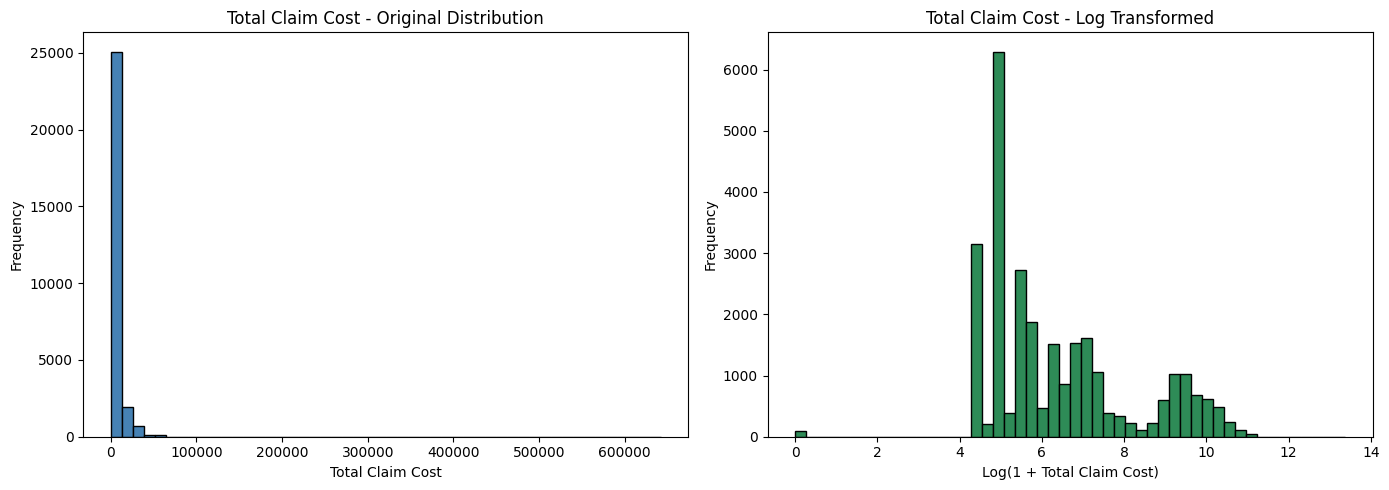

Claim cost distribution visualization completed.


In [42]:
# Visualize claim cost distribution before and after log transformation

import numpy as np
import matplotlib.pyplot as plt

# Create log-transformed claim cost
encounters["COST_LOG"] = np.log1p(
    encounters["TOTAL_CLAIM_COST"]
)

# Create comparison plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original cost distribution
encounters["TOTAL_CLAIM_COST"].plot(
    kind="hist",
    bins=50,
    ax=axes[0],
    color="steelblue",
    edgecolor="black",
    title="Total Claim Cost - Original Distribution"
)

axes[0].set_xlabel("Total Claim Cost")
axes[0].set_ylabel("Frequency")

# Log-transformed cost distribution
encounters["COST_LOG"].plot(
    kind="hist",
    bins=50,
    ax=axes[1],
    color="seagreen",
    edgecolor="black",
    title="Total Claim Cost - Log Transformed"
)

axes[1].set_xlabel("Log(1 + Total Claim Cost)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print("Claim cost distribution visualization completed.")

In [43]:
# Final data quality classification and approval gate

quality_checks = []


def register_quality_check(
    check_name,
    issue_count,
    severity
):

    quality_checks.append({
        "Validation_Check": check_name,
        "Issue_Count": int(issue_count),
        "Severity": severity
    })


# Register critical validation failures
register_quality_check(
    "Mandatory Validation Failures",
    int((~final_validation_report["Passed"]).sum()),
    "Critical"
)


# Register clinical and temporal warnings
register_quality_check(
    "Encounters After Death",
    encounters["FLAG_AFTER_DEATH"].sum(),
    "Warning"
)

register_quality_check(
    "Encounters Before Birth",
    encounters["FLAG_BEFORE_BIRTH"].sum(),
    "Warning"
)

register_quality_check(
    "Procedures Outside Encounter",
    procedures["FLAG_OUTSIDE_ENCOUNTER"].sum(),
    "Warning"
)

register_quality_check(
    "Invalid Patient Ages",
    patients["FLAG_INVALID_AGE"].sum(),
    "Warning"
)

register_quality_check(
    "Extreme Encounter Durations",
    encounters["FLAG_EXTREME_DURATION"].sum(),
    "Warning"
)


# Register informational findings
register_quality_check(
    "Zero-Cost Encounters",
    encounters["FLAG_ZERO_COST"].sum(),
    "Information"
)

register_quality_check(
    "Encounter Cost Outliers",
    encounters["FLAG_COST_OUTLIER"].sum(),
    "Information"
)

register_quality_check(
    "Procedure Cost Outliers",
    procedures["FLAG_COST_OUTLIER"].sum(),
    "Information"
)


# Generate final quality report
quality_status_report = pd.DataFrame(
    quality_checks
)

display(quality_status_report)


# Calculate severity totals
severity_summary = (
    quality_status_report
    .groupby("Severity", as_index=False)["Issue_Count"]
    .sum()
)

display(severity_summary)


# Evaluate final dataset readiness
critical_errors = quality_status_report.loc[
    quality_status_report["Severity"] == "Critical",
    "Issue_Count"
].sum()

warnings = quality_status_report.loc[
    quality_status_report["Severity"] == "Warning",
    "Issue_Count"
].sum()


if critical_errors > 0:

    raise ValueError(
        "Critical data quality issues remain unresolved."
    )

elif warnings > 0:

    print("STATUS: PASSED WITH WARNINGS")
    print("Mandatory checks passed.")
    print("Review flagged records before sensitive analysis.")

else:

    print("STATUS: PASSED")
    print("All mandatory quality checks passed.")

,Validation_Check,Issue_Count,Severity
0,Mandatory Validation Failures,0,Critical
1,Encounters After Death,68,Warning
2,Encounters Before Birth,0,Warning
3,Procedures Outside Encounter,28849,Warning
4,Invalid Patient Ages,0,Warning
5,Extreme Encounter Durations,9,Warning
6,Zero-Cost Encounters,89,Information
7,Encounter Cost Outliers,1184,Information
8,Procedure Cost Outliers,0,Information


,Severity,Issue_Count
0,Critical,0
1,Information,1273
2,Warning,28926


STATUS: PASSED WITH WARNINGS
Mandatory checks passed.
Review flagged records before sensitive analysis.


In [44]:
# Final look at the cleaned encounters table (types + sample)
encounters.info()
encounters.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27891 entries, 0 to 27890
Data columns (total 36 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Id                     27891 non-null  string        
 1   START                  27891 non-null  datetime64[ns]
 2   STOP                   27891 non-null  datetime64[ns]
 3   PATIENT                27891 non-null  string        
 4   ORGANIZATION           27891 non-null  string        
 5   PAYER                  27891 non-null  string        
 6   ENCOUNTERCLASS         27891 non-null  string        
 7   CODE                   27891 non-null  string        
 8   DESCRIPTION            27891 non-null  string        
 9   BASE_ENCOUNTER_COST    27891 non-null  float64       
 10  TOTAL_CLAIM_COST       27891 non-null  float64       
 11  PAYER_COVERAGE         27891 non-null  float64       
 12  REASONCODE             8350 non-null   string        
 13  R

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION,ENCOUNTER_DATE,YEAR,MONTH,MONTH_NAME,DAY_OF_WEEK,HOUR,DURATION_MIN,PAYER_NAME,IS_INSURED,PATIENT_PAYS,COVERAGE_RATE,AGE_AT_ENCOUNTER,PROCEDURE_COUNT,FLAG_BEFORE_BIRTH,FLAG_AFTER_DEATH,FLAG_INVALID_TIME,FLAG_ZERO_COST,FLAG_NEGATIVE_COST,FLAG_COVERAGE_GT_COST,FLAG_COST_OUTLIER,FLAG_EXTREME_DURATION,COST_LOG
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,Ambulatory,185347001,Encounter for problem (procedure),85.55,"1,018.02",0.00,<NA>,<NA>,2011-01-02,2011,1,January,Sunday,9,212.00,No Insurance,False,"1,018.02",0.00,82,1,False,False,False,False,False,False,False,False,6.93
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,Outpatient,308335008,Patient encounter procedure,142.58,"2,619.36",0.00,<NA>,<NA>,2011-01-03,2011,1,January,Monday,5,17.05,No Insurance,False,"2,619.36",0.00,46,1,False,False,False,False,False,False,False,False,7.87
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03 14:32:11,2011-01-03 14:47:11,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,Outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,<NA>,<NA>,2011-01-03,2011,1,January,Monday,14,15.00,Medicare,True,156.32,0.66,86,0,False,False,False,False,False,False,False,False,6.14
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03 16:24:45,2011-01-03 16:39:45,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,Wellness,162673000,General examination of patient (procedure),136.80,"1,784.24",0.00,<NA>,<NA>,2011-01-03,2011,1,January,Monday,16,15.00,No Insurance,False,"1,784.24",0.00,87,0,False,False,False,False,False,False,False,False,7.49
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03 17:36:53,2011-01-03 17:51:53,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,Ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,55822004,Hyperlipidemia,2011-01-03,2011,1,January,Monday,17,15.00,Anthem,True,234.72,0.00,58,0,False,False,False,False,False,False,False,False,5.46


*italicized text*## 4. Relational Database
Relationships:
- `encounters.PATIENT → patients.Id`
- `encounters.PAYER → payers.Id`
- `encounters.ORGANIZATION → organizations.Id`
- `procedures.ENCOUNTER → encounters.Id`
- `encounters.START → Calendar.Date`

In [45]:
print("Encounters with unknown patient:  ", (~encounters['PATIENT'].isin(patients['Id'])).sum())
print("Encounters with unknown payer:    ", (~encounters['PAYER'].isin(payers['Id'])).sum())
print("Procedures with unknown encounter:", (~procedures['ENCOUNTER'].isin(encounters['Id'])).sum())

Encounters with unknown patient:   0
Encounters with unknown payer:     0
Procedures with unknown encounter: 0


### 4.1 Calendar table

In [46]:
calendar = pd.DataFrame({"Date": pd.date_range(encounters["START"].min().normalize(), encounters["STOP"].max().normalize())})
calendar["Day"]     = calendar["Date"].dt.day
calendar["DayName"] = calendar["Date"].dt.day_name()
calendar["Month"]   = calendar["Date"].dt.month_name()
calendar["Quarter"] = "Q" + calendar["Date"].dt.quarter.astype(str)
calendar["Year"]    = calendar["Date"].dt.year
calendar.head()

,Date,Day,DayName,Month,Quarter,Year
0,2011-01-02,2,Sunday,January,Q1,2011
1,2011-01-03,3,Monday,January,Q1,2011
2,2011-01-04,4,Tuesday,January,Q1,2011
3,2011-01-05,5,Wednesday,January,Q1,2011
4,2011-01-06,6,Thursday,January,Q1,2011


### 4.2 Create the database

In [47]:
conn = sqlite3.connect("hospital.db")
patients.to_sql("Patients", conn, if_exists="replace", index=False)
encounters.to_sql("Encounters", conn, if_exists="replace", index=False)
procedures.to_sql("Procedures", conn, if_exists="replace", index=False)
payers.to_sql("Payers", conn, if_exists="replace", index=False)
organizations.to_sql("Organizations", conn, if_exists="replace", index=False)
calendar.to_sql("Calendar", conn, if_exists="replace", index=False)

4053

### 4.3 SQL queries

In [48]:
query = '''
SELECT e.Id, e.START, e.ENCOUNTERCLASS, e.DESCRIPTION, e.TOTAL_CLAIM_COST, e.PAYER_COVERAGE,
       p.GENDER, p.BIRTHDATE, p.CITY, py.NAME AS Payer
FROM Encounters e
JOIN Patients p ON e.PATIENT = p.Id
JOIN Payers py  ON e.PAYER = py.Id
'''
df = pd.read_sql(query, conn)
df.head()

,Id,START,ENCOUNTERCLASS,DESCRIPTION,TOTAL_CLAIM_COST,PAYER_COVERAGE,GENDER,BIRTHDATE,CITY,Payer
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02 09:26:36,Ambulatory,Encounter for problem (procedure),"1,018.02",0.00,Male,1928-08-25 00:00:00,Boston,No Insurance
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03 05:44:39,Outpatient,Patient encounter procedure,"2,619.36",0.00,Female,1964-01-05 00:00:00,Boston,No Insurance
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03 14:32:11,Outpatient,Encounter for check up (procedure),461.59,305.27,Female,1924-06-30 00:00:00,Boston,Medicare
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03 16:24:45,Wellness,General examination of patient (procedure),"1,784.24",0.00,Male,1923-05-21 00:00:00,Boston,No Insurance
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03 17:36:53,Ambulatory,Follow-up encounter,234.72,0.00,Male,1952-11-02 00:00:00,Braintree,Anthem


In [49]:
pd.read_sql('''
SELECT py.NAME AS Payer, COUNT(*) AS Encounters, ROUND(AVG(e.TOTAL_CLAIM_COST), 2) AS AvgCost
FROM Encounters e
JOIN Payers py ON e.PAYER = py.Id
GROUP BY py.NAME
ORDER BY Encounters DESC
''', conn)

,Payer,Encounters,AvgCost
0,Medicare,11371,"2,167.55"
1,No Insurance,8807,"5,593.20"
2,Medicaid,1443,"6,205.22"
3,Humana,1084,"3,269.30"
4,Aetna,936,"2,767.05"
5,Blue Cross Blue Shield,925,"3,245.58"
6,Dual Eligible,912,"1,696.19"
7,UnitedHealthcare,900,"2,848.34"
8,Cigna Health,809,"2,996.95"
9,Anthem,704,"4,236.81"


In [50]:
pd.read_sql('''
SELECT DESCRIPTION, COUNT(*) AS Times
FROM Procedures
GROUP BY DESCRIPTION
ORDER BY Times DESC
LIMIT 10
''', conn)

,DESCRIPTION,Times
0,Assessment of health and social care needs (pr...,4596
1,Hospice care (regime/therapy),4098
2,Depression screening using Patient Health Ques...,3614
3,Depression screening (procedure),3614
4,Assessment of substance use (procedure),2906
5,Renal dialysis (procedure),2746
6,Assessment using Morse Fall Scale (procedure),2422
7,Assessment of anxiety (procedure),2288
8,Medication Reconciliation (procedure),2284
9,Screening for drug abuse (procedure),1484


In [ ]:
pd.read_sql('''
SELECT c.Year, COUNT(*) AS Encounters
FROM Encounters e
JOIN Calendar c ON date(e.START) = date(c.Date)
GROUP BY c.Year
''', conn)

## 5. Save

In [ ]:
# Compatibility bridge for the team's existing EDA cells.
# The original EDA cells read encounters_clean.csv from /content.
from pathlib import Path
import shutil

cleaned_encounters = Path("/content/hospital_cleaned_data/encounters_clean.csv")
destination = Path("/content/encounters_clean.csv")

if cleaned_encounters.exists():
    shutil.copy2(cleaned_encounters, destination)
    print("Existing EDA input path prepared via file copy.")
else:
    # If the export cell hasn't run, use the cleaned DataFrame currently in memory
    encounters.to_csv(destination, index=False)
    print("Existing EDA input path prepared directly from memory.")

In [ ]:
# Export cleaned datasets and data quality reports

from pathlib import Path
import shutil


# Verify mandatory quality checks before export
if not final_validation_report["Passed"].all():
    raise ValueError(
        "Export blocked: mandatory data quality checks failed."
    )


# Create output directory
OUTPUT_DIR = Path("/content/hospital_cleaned_data")

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Prepare final cleaned datasets
final_datasets = {
    "patients": patients,
    "encounters": encounters,
    "procedures": procedures,
    "payers": payers,
    "organizations": organizations
}


# Export cleaned CSV files
for name, dataframe in final_datasets.items():

    file_path = OUTPUT_DIR / f"{name}_clean.csv"

    dataframe.to_csv(
        file_path,
        index=False
    )

    print(f"Exported: {file_path.name}")


# Prepare data quality reports
quality_reports = {
    "raw_summary": raw_summary,
    "clean_summary": clean_summary,
    "conversion_report": conversion_report,
    "duplicate_audit": duplicate_audit,
    "integrity_report": integrity_report,
    "validation_report": validation_report,
    "logical_validation_report": logical_validation_report,
    "outlier_summary": outlier_summary,
    "final_validation_report": final_validation_report,
    "quality_status_report": quality_status_report,
    "after_death_summary": after_death_summary,
    "procedure_timing_report": procedure_timing_report
}


# Export quality reports
for name, report in quality_reports.items():

    report.to_csv(
        OUTPUT_DIR / f"{name}.csv",
        index=True
    )


# Export flagged records for review
after_death_encounters.to_csv(
    OUTPUT_DIR / "encounters_after_death_review.csv",
    index=False
)

outside_procedures.to_csv(
    OUTPUT_DIR / "procedures_timing_review.csv",
    index=False
)


# Create downloadable ZIP archive
zip_path = shutil.make_archive(
    "/content/hospital_cleaned_data",
    "zip",
    OUTPUT_DIR
)

print("\nAll cleaned datasets and reports exported successfully.")

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. تحميل البيانات وتحديد الأعمدة الكمية
df = pd.read_csv("encounters_clean.csv")
num_cols = [
    'TOTAL_CLAIM_COST',
    'PATIENT_PAYS',
    'PAYER_COVERAGE',
    'PROCEDURE_COUNT',
    'AGE_AT_ENCOUNTER',
    'DURATION_MIN',
]

# 2. حساب مصفوفة ارتباط سبيرمان
spearman_corr = df[num_cols].corr(method='spearman')

# 3. رسم الخريطة الحرارية المعتمدة أكاديمياً
plt.figure(figsize=(9, 7))
sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.8,
    cbar_kws={'label': 'Spearman Correlation (r_s)'},
)

plt.title(
    "Spearman Correlation Matrix Across Numeric Features",
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()

# حفظ وعرض الرسمة
plt.savefig("1_spearman_heatmap.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. تحميل البيانات وتجهيز المقياس اللوجارتمي للتكلفة
df = pd.read_csv("encounters_clean.csv")
df['COST_LOG'] = np.log1p(df['TOTAL_CLAIM_COST'])

# 2. رسم Box Plot وتفادي تحذير palette المحدث
plt.figure(figsize=(10, 6))
sns.boxplot(
    x='ENCOUNTERCLASS',
    y='COST_LOG',
    hue='ENCOUNTERCLASS',  # التعديل هنا لتفادي FutureWarning
    data=df,
    palette='Set2',
    showfliers=False
)

plt.title("Kruskal-Wallis Test: Total Claim Cost across Encounter Classes (p < 0.001)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Encounter Class", fontsize=11, fontweight='bold')
plt.ylabel("Total Claim Cost (Log Scale)", fontsize=11, fontweight='bold')
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# حفظ وعرض الرسمة
plt.savefig("2_kruskal_boxplot.png", dpi=300)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. تحميل البيانات
df = pd.read_csv("encounters_clean.csv")

# 2. رسم المخطط شريطي التجمعي المشهور
plt.figure(figsize=(10, 6))
sns.countplot(
    x='ENCOUNTERCLASS',
    hue='FLAG_COST_OUTLIER',
    data=df,
    palette='vlag',
)

plt.title(
    "Chi-Square Test: Cost Outliers Distribution by Encounter Class (Cramér's V = 0.2738)",
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel("Encounter Class", fontsize=11, fontweight='bold')
plt.ylabel("Number of Encounters", fontsize=11, fontweight='bold')
plt.legend(title="Outlier Flag", labels=["Normal Cost (0)", "High Outlier (1)"])
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# حفظ وعرض الرسمة
plt.savefig("3_categorical_chi2_bars.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. تحميل البيانات وتجهيز المقياس اللوجارتمي
df = pd.read_csv("encounters_clean.csv")
df['PATIENT_PAYS_LOG'] = np.log1p(df['PATIENT_PAYS'])

# 2. رسم Box Plot لمقارنة المجموعتين
plt.figure(figsize=(8, 6))
sns.boxplot(
    x='IS_INSURED',
    y='PATIENT_PAYS_LOG',
    hue='IS_INSURED',
    data=df,
    palette='Set1',
    showfliers=False,
)

plt.title(
    "Mann-Whitney U Test: Patient Out-of-Pocket Payment by Insurance Status (p"
    " < 0.001)",
    fontsize=11,
    fontweight='bold',
    pad=15,
)
plt.xlabel("Insurance Status (Is Insured)", fontsize=10, fontweight='bold')
plt.ylabel("Patient Pays (Log Scale)", fontsize=10, fontweight='bold')
plt.xticks(ticks=[0, 1], labels=["Uninsured (False)", "Insured (True)"])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# 3. حفظ وعرض الرسمة
plt.savefig("4_mwu_insurance_payment.png", dpi=300)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. تحميل البيانات وتجهيز المقياس اللوجارتمي للتكلفة
df = pd.read_csv("encounters_clean.csv")
df['COST_LOG'] = np.log1p(df['TOTAL_CLAIM_COST'])

# 2. رسم Scatter Plot مع خط اتجاه الانحدار (Trendline)
plt.figure(figsize=(9, 6))
sns.regplot(
    x='PROCEDURE_COUNT',
    y='COST_LOG',
    data=df,
    scatter_kws={'alpha': 0.3, 'color': 'teal'},
    line_kws={'color': 'red', 'linewidth': 2},
)

plt.title(
    "Spearman Correlation: Procedure Count vs. Total Claim Cost (r_s = +0.673,"
    " p < 0.001)",
    fontsize=11,
    fontweight='bold',
    pad=15,
)
plt.xlabel("Procedure Count", fontsize=10, fontweight='bold')
plt.ylabel("Total Claim Cost (Log Scale)", fontsize=10, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# 3. حفظ وعرض الرسمة
plt.savefig("5_spearman_scatter_trendline.png", dpi=300)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. تحميل البيانات وتصفية السنوات المكتملة (2011 - 2021)
df = pd.read_csv("encounters_clean.csv")
df_full_years = df[df['YEAR'] < 2022]

# 2. تجميع البيانات سنوياً
yearly_trend = (
    df_full_years.groupby('YEAR')
    .agg(
        encounters=('Id', 'count'),
        total_cost=('TOTAL_CLAIM_COST', lambda x: x.sum() / 1e6),  # بالملايين
    )
    .reset_index()
)

# 3. إنشاء رسم بياني مزدوج المحاور (Bar + Line Chart)
fig, ax1 = plt.subplots(figsize=(10, 5))

# المحور الأول: عدد الزيارات (أعمدة)
color = 'teal'
ax1.set_xlabel('Year', fontweight='bold', fontsize=11)
ax1.set_ylabel('Total Encounters', color=color, fontweight='bold', fontsize=11)
ax1.bar(
    yearly_trend['YEAR'],
    yearly_trend['encounters'],
    color=color,
    alpha=0.4,
    width=0.5,
)
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# المحور الثاني: التكلفة الإجمالية (خط)
ax2 = ax1.twinx()
color = 'darkred'
ax2.set_ylabel(
    'Total Claim Cost ($ Millions)', color=color, fontweight='bold', fontsize=11
)
ax2.plot(
    yearly_trend['YEAR'],
    yearly_trend['total_cost'],
    color=color,
    marker='o',
    linewidth=2.5,
)
ax2.tick_params(axis='y', labelcolor=color)

plt.title(
    "Yearly Trend of Medical Encounters & Total Claim Costs (2011 - 2021)",
    fontsize=13,
    fontweight='bold',
    pad=15,
)
fig.tight_layout()
plt.savefig("eda_1_time_series.png", dpi=300)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. تحميل البيانات المنظفة
df = pd.read_csv("encounters_clean.csv")

# 2. تجميع البيانات وتحديد أعلى 10 أسباب طبية حسَب التكرار
reason_stats = (
    df.groupby('REASONDESCRIPTION')
    .agg(
        count=('Id', 'count'),
        mean_cost=('TOTAL_CLAIM_COST', 'mean'),
        median_cost=('TOTAL_CLAIM_COST', 'median'),
        mean_procedures=('PROCEDURE_COUNT', 'mean'),
    )
    .reset_index()
    .sort_values(by='count', ascending=False)
    .head(10)
)

# 3. رسم المخطط الأفقي لمتوسط التكلفة لكل تشخيص (خالٍ تماماً من التحذيرات)
plt.figure(figsize=(10, 6))
sns.barplot(
    x='mean_cost',
    y='REASONDESCRIPTION',
    hue='REASONDESCRIPTION',  # يمنع ظهور FutureWarning
    data=reason_stats,
    palette='magma',
)
plt.legend([], frameon=False)  # إخفاء مربع الإيضاح المكرر لسلامة الشكل

plt.title(
    "Top 10 Clinical Reasons by Average Claim Cost ($)",
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.xlabel("Average Claim Cost ($)", fontsize=10, fontweight='bold')
plt.ylabel("Clinical Reason / Diagnosis", fontsize=10, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

# 4. حفظ وعرض الرسمة البيانية عالية الجودة
plt.savefig("eda_2_clinical_reasons_fixed.png", dpi=300)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. تحميل البيانات وتجميع إحصائيات التكلفة حسب شركة التأمين
df = pd.read_csv("encounters_clean.csv")

payer_stats = (
    df.groupby('PAYER_NAME')
    .agg(
        total_encounters=('Id', 'count'),
        total_claim_cost=('TOTAL_CLAIM_COST', 'sum'),
        payer_coverage=('PAYER_COVERAGE', 'sum'),
        patient_pays=('PATIENT_PAYS', 'sum'),
        mean_coverage_rate=('COVERAGE_RATE', 'mean'),
    )
    .reset_index()
    .sort_values(by='total_claim_cost', ascending=False)
)

# 2. رسم المخطط الأفقي وإسناد hue='PAYER_NAME' لمنع التحذير
plt.figure(figsize=(10, 6))
sns.barplot(
    x='total_claim_cost',
    y='PAYER_NAME',
    hue='PAYER_NAME',  # حل مشكلة FutureWarning
    data=payer_stats,
    palette='magma',
)
plt.legend([], frameon=False)  # إخفاء مربع الإيضاح المكرر

plt.title(
    "Total Claim Costs by Health Insurance Payer ($)",
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.xlabel("Total Claim Cost ($)", fontsize=10, fontweight='bold')
plt.ylabel("Insurance Payer Name", fontsize=10, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

# 3. حفظ وعرض الرسمة
plt.savefig("eda_3_financial_payer_breakdown.png", dpi=300)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. تحميل البيانات وتقسيم الأعمار إلى شرائح
df = pd.read_csv("encounters_clean.csv")
bins = [0, 18, 35, 50, 65, 80, 120]
labels = [
    'Child (0-18)',
    'Young Adult (19-35)',
    'Adult (36-50)',
    'Middle-Aged (51-65)',
    'Senior (66-80)',
    'Elderly (80+)',
]
df['AGE_GROUP'] = pd.cut(
    df['AGE_AT_ENCOUNTER'], bins=bins, labels=labels, right=True
)

# 2. تجميع البيانات ديموغرافياً
age_summary = (
    df.groupby('AGE_GROUP', observed=False)
    .agg(
        total_encounters=('Id', 'count'),
        mean_cost=('TOTAL_CLAIM_COST', 'mean'),
        median_cost=('TOTAL_CLAIM_COST', 'median'),
        total_cost=('TOTAL_CLAIM_COST', 'sum'),
    )
    .reset_index()
)

# 3. رسم المخطط الأفقي لتوزيع الزيارات لكل فئة عمرية
plt.figure(figsize=(10, 6))
sns.barplot(
    x='total_encounters',
    y='AGE_GROUP',
    hue='AGE_GROUP',  # خالي من FutureWarning
    data=age_summary,
    palette='Blues_r',
)
plt.legend([], frameon=False)

plt.title(
    "Encounters Distribution across Patient Age Groups",
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.xlabel("Total Encounters", fontsize=10, fontweight='bold')
plt.ylabel("Age Group", fontsize=10, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

# 4. حفظ وعرض الرسمة
plt.savefig("eda_4_age_demographics.png", dpi=300)
plt.show()

In [ ]:
import pandas as pd

# 1. تحميل البيانات
df = pd.read_csv("encounters_clean.csv")

# 2. حساب المؤشرات الرئيسية (KPIs)
kpis = {
    "Total Encounters": f"{len(df):,}",
    "Unique Patients": f"{df['PATIENT'].nunique():,}",
    "Total Claim Cost": f"${df['TOTAL_CLAIM_COST'].sum():,.2f}",
    "Total Patient Pays": f"${df['PATIENT_PAYS'].sum():,.2f}",
    "Total Payer Coverage": f"${df['PAYER_COVERAGE'].sum():,.2f}",
    "Overall Coverage Rate": f"{(df['PAYER_COVERAGE'].sum() / df['TOTAL_CLAIM_COST'].sum()) * 100:.2f}%",
    "Mean Claim Cost": f"${df['TOTAL_CLAIM_COST'].mean():,.2f}",
    "Median Claim Cost": f"${df['TOTAL_CLAIM_COST'].median():,.2f}",
    "Cost Outlier Rate": f"{(df['FLAG_COST_OUTLIER'].sum() / len(df)) * 100:.2f}%",
}

# 3. عرض المؤشرات في جدول مربي
kpi_df = pd.DataFrame(list(kpis.items()), columns=["KPI Name", "Value"])
print(kpi_df.to_string(index=False))

## 10. Interactive Dashboards

The original project cells above are preserved. The following cells install the dashboard dependencies, build five responsive dashboard pages, and expose the app through a browser link.

In [ ]:
!pip -q install dash plotly scipy

In [ ]:
# Hospital Analytics Dashboard
# Built with Plotly Dash. All interface text is in English.

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import plotly.express as px
import plotly.graph_objects as go
from dash import Dash, dcc, html, Input, Output, State, no_update

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = Path("/content/hospital_cleaned_data")
if not DATA_DIR.exists():
    DATA_DIR = Path.cwd() / "hospital_cleaned_data"

def read_csv_required(filename):
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run the original notebook through its export step first."
        )
    return pd.read_csv(path, low_memory=False)

encounters = read_csv_required("encounters_clean.csv")
patients = read_csv_required("patients_clean.csv")
procedures = read_csv_required("procedures_clean.csv")
payers = read_csv_required("payers_clean.csv")
organizations = read_csv_required("organizations_clean.csv")

for col in ["START", "STOP", "ENCOUNTER_DATE"]:
    if col in encounters.columns:
        encounters[col] = pd.to_datetime(encounters[col], errors="coerce")
for col in ["BIRTHDATE", "DEATHDATE"]:
    if col in patients.columns:
        patients[col] = pd.to_datetime(patients[col], errors="coerce")

NUMERIC_COLUMNS = [
    "TOTAL_CLAIM_COST", "PATIENT_PAYS", "PAYER_COVERAGE",
    "PROCEDURE_COUNT", "AGE_AT_ENCOUNTER", "DURATION_MIN",
    "COVERAGE_RATE", "YEAR", "MONTH", "HOUR"
]
for col in NUMERIC_COLUMNS:
    if col in encounters.columns:
        encounters[col] = pd.to_numeric(encounters[col], errors="coerce")

if "PAYER_NAME" not in encounters.columns and {"PAYER", "Id"}.issubset(encounters.columns) and {"Id", "NAME"}.issubset(payers.columns):
    encounters = encounters.merge(
        payers[["Id", "NAME"]].rename(columns={"Id": "PAYER", "NAME": "PAYER_NAME"}),
        on="PAYER", how="left"
    )
if "GENDER" not in encounters.columns and "PATIENT" in encounters.columns and {"Id", "GENDER"}.issubset(patients.columns):
    encounters = encounters.merge(
        patients[["Id", "GENDER"]].rename(columns={"Id": "PATIENT"}),
        on="PATIENT", how="left"
    )
if "AGE_AT_ENCOUNTER" not in encounters.columns and "PATIENT" in encounters.columns and {"Id", "BIRTHDATE"}.issubset(patients.columns):
    birth = patients.set_index("Id")["BIRTHDATE"]
    b = encounters["PATIENT"].map(birth)
    encdate = encounters["START"]
    birthday_not_reached = ((encdate.dt.month < b.dt.month) |
        ((encdate.dt.month == b.dt.month) & (encdate.dt.day < b.dt.day)))
    encounters["AGE_AT_ENCOUNTER"] = (
        encdate.dt.year - b.dt.year - birthday_not_reached.astype("float")
    )

if "AGE_GROUP" not in encounters.columns and "AGE_AT_ENCOUNTER" in encounters.columns:
    encounters["AGE_GROUP" ] = pd.cut(
        encounters["AGE_AT_ENCOUNTER"],
        bins=[-1, 17, 34, 49, 64, 79, 120],
        labels=["0-17", "18-34", "35-49", "50-64", "65-79", "80+"]
    ).astype("string")

for col, default in [
    ("REASONDESCRIPTION", "Not available"),
    ("PAYER_NAME", "Unknown"),
    ("ENCOUNTERCLASS", "Unknown"),
    ("GENDER", "Unknown")
]:
    if col not in encounters.columns:
        encounters[col] = default

date_min = encounters["START"].min()
date_max = encounters["START"].max()
if pd.isna(date_min) or pd.isna(date_max):
    date_min, date_max = pd.Timestamp("2000-01-01"), pd.Timestamp("2000-12-31")
date_min_s, date_max_s = date_min.strftime("%Y-%m-%d"), date_max.strftime("%Y-%m-%d")

PALETTE = ["#A555EC", "#D09CFA", "#B8DFFF", "#FFFFD0", "#F3CCFF", "#7DCEFA"]
INK = "#282344"
MUTED = "#77718F"
GRID = "#EEEAF8"

def money(x):
    return "$" + format(float(x or 0), ",.0f")

def safe_sum(df, col):
    return float(df[col].fillna(0).sum()) if col in df.columns else 0.0

def safe_mean(df, col):
    return float(df[col].dropna().mean()) if col in df.columns and df[col].notna().any() else 0.0

def base_figure(fig, height=300, show_legend=False):
    fig.update_layout(
        template="plotly_white", height=height, margin=dict(l=12, r=12, t=42, b=12),
        paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)",
        font=dict(family="Inter, Arial", color=INK, size=11),
        title=dict(font=dict(size=14, color=INK), x=0.02),
        showlegend=show_legend,
        legend=dict(orientation="h", y=-0.22, x=0),
        hoverlabel=dict(bgcolor="#FFFFFF", font_color=INK)
    )
    fig.update_xaxes(showgrid=True, gridcolor=GRID, zeroline=False)
    fig.update_yaxes(showgrid=True, gridcolor=GRID, zeroline=False)
    return fig

def empty_fig(message="No records match the selected filters."):
    fig = go.Figure()
    fig.add_annotation(text=message, x=0.5, y=0.5, xref="paper", yref="paper",
                       showarrow=False, font=dict(color=MUTED, size=13))
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    return base_figure(fig, show_legend=False)

def filtered_data(start, end, encounter_class, gender, payer, page="overview", focus="All"):
    d = encounters.copy()
    d = d[d["START"].notna()]
    if start:
        d = d[d["START"] >= pd.to_datetime(start)]
    if end:
        d = d[d["START"] < (pd.to_datetime(end) + pd.Timedelta(days=1))]
    if encounter_class and encounter_class != "All":
        d = d[d["ENCOUNTERCLASS"].astype(str) == encounter_class]
    if gender and gender != "All":
        d = d[d["GENDER"].astype(str) == gender]
    if payer and payer != "All":
        d = d[d["PAYER_NAME"].astype(str) == payer]
    focus_fields = {
        "overview": "ENCOUNTERCLASS",
        "patients": "AGE_GROUP",
        "clinical": "REASONDESCRIPTION",
        "finance": "PAYER_NAME",
        "trends": "MONTH_NAME"
    }
    if focus and focus != "All":
        field = focus_fields.get(page)
        if field == "MONTH_NAME":
            d = d[d["START"].dt.month_name() == focus]
        elif field and field in d.columns:
            d = d[d[field].astype(str) == focus]
    return d

def kpi_card(label, value, note=""):
    return html.Div([
        html.Div(label, className="kpi-label"),
        html.Div(value, className="kpi-value"),
        html.Div(note, className="kpi-note")
    ], className="kpi-card")

def chart_title(title):
    return html.Div(title, className="chart-title")

NAV = [
    ("overview", "⌂", "Overview"),
    ("patients", "♙", "Patients"),
    ("clinical", "✚", "Clinical"),
    ("finance", "＄", "Finance"),
    ("trends", "◷", "Trends")
]

CUSTOM_CSS = """
:root{--purple:#A555EC;--lav:#D09CFA;--pink:#F3CCFF;--blue:#DDF2FF;--ink:#282344}
*{box-sizing:border-box} body{margin:0;background:#F8F7FF;color:var(--ink);font-family:Inter,Arial,sans-serif}
.app-shell{width:100%;max-width:1600px;margin:auto;padding:18px 22px 28px;overflow-x:hidden}
.topbar{display:flex;align-items:center;gap:18px;flex-wrap:wrap;margin-bottom:14px}
.brand{display:flex;align-items:center;gap:9px;min-width:130px}.brand-mark{width:38px;height:38px;border-radius:10px;background:linear-gradient(135deg, var(--purple), var(--lav));color:#FFF;display:flex;align-items:center;justify-content:center;font-size:22px;font-weight:700}
.brand-text{display:flex;flex-direction:column}.brand-title{font-size:16px;font-weight:800;letter-spacing:-0.2px;line-height:1.2;color:var(--ink)}.brand-subtitle{font-size:11px;color:#77718F}
.nav-tabs{display:flex;gap:4px;background:#FFF;padding:4px;border-radius:10px;border:1px solid #EEEAF8}
.nav-tab{display:flex;align-items:center;gap:6px;padding:7px 14px;border-radius:7px;color:#77718F;text-decoration:none;font-size:12px;font-weight:600;transition:all 0.2s}
.nav-tab:hover{background:#F9F8FD;color:var(--purple)}
.nav-tab-active{background:linear-gradient(135deg, var(--purple), var(--lav));color:#FFF!important}
.control-pane{display:grid;grid-template-columns:repeat(auto-fit, minmax(180px, 1fr));gap:12px;background:#FFF;padding:16px;border-radius:12px;border:1px solid #EEEAF8;margin-bottom:18px}
.control-group{display:flex;flex-direction:column;gap:5px}.control-label{font-size:11px;font-weight:700;color:#77718F;text-transform:uppercase;letter-spacing:0.3px}
.dash-dropdown .Select-control{border:1px solid #E4DFFA!important;border-radius:7px!important;height:35px!important}
.dash-date-picker{border:1px solid #E4DFFA!important;border-radius:7px!important;padding:4px!important;width:100%!important;height:35px!important}
.kpi-row{display:grid;grid-template-columns:repeat(auto-fit, minmax(160px, 1fr));gap:12px;margin-bottom:18px}
.kpi-card{background:#FFF;padding:14px;border-radius:12px;border:1px solid #EEEAF8;box-shadow:0 1px 3px rgba(40,35,68,0.02);display:flex;flex-direction:column;gap:2px}
.kpi-label{font-size:11px;font-weight:600;color:#77718F;text-transform:uppercase}
.kpi-value{font-size:20px;font-weight:800;color:var(--ink);letter-spacing:-0.5px}
.kpi-note{font-size:10px;color:#77718F;margin-top:2px}
.dashboard-grid{display:grid;grid-template-columns:repeat(12, 1fr);gap:18px}
.col-12{grid-column:span 12}.col-8{grid-column:span 8}.col-6{grid-column:span 6}.col-4{grid-column:span 4}.col-3{grid-column:span 3}
.chart-card{background:#FFF;border-radius:14px;border:1px solid #EEEAF8;padding:16px;position:relative;box-shadow:0 1px 3px rgba(40,35,68,0.02)}
.chart-title{font-size:13px;font-weight:700;color:var(--ink);margin-bottom:12px;display:flex;align-items:center;gap:6px}
.table-container{overflow-x:auto;max-height:270px}
.dash-table{width:100%;border-collapse:collapse}.dash-table th{background:#F9F8FD;padding:8px 10px;text-align:left;font-size:10px;font-weight:700;color:#77718F;text-transform:uppercase;border-bottom:1px solid #EEEAF8}
.dash-table td{padding:8px 10px;font-size:11px;color:var(--ink);border-bottom:1px solid #F6F4FC}
.dash-table tr:hover td{background:#F9F8FD}
@media(max-width:800px){.col-8,.col-6,.col-4,.col-3{grid-column:span 12}.topbar{flex-direction:column;align-items:stretch}}
"""

app = Dash(__name__, title="Massachusetts General Hospital Intelligence", suppress_callback_exceptions=True)
app.index_string = f"""<!DOCTYPE html><html><head>{{%metas%}}<meta name="viewport" content="width=device-width, initial-scale=1.0"><title>{{%title%}}</title>{{%favicon%}}<style>{CUSTOM_CSS}</style>{{%css%}}</head><body style="margin:0;padding:0;background:#F8F7FF">{{%app_entry%}}<footer>{{%config%}}<span></span>{{%scripts%}}{{%renderer%}}</footer></body></html>"""

app.layout = html.Div([
    dcc.Store(id="app-page", storage_type="session", data="overview"),
    dcc.Store(id="focus-filter", storage_type="session", data="All"),
    html.Div([
        html.Div([
            html.Div([
                html.Div("M", className="brand-mark"),
                html.Div([
                    html.Div("Massachusetts General", className="brand-title"),
                    html.Div("Intelligence Portal", className="brand-subtitle")
                ], className="brand-text")
            ], className="brand"),
            html.Div(id="navigation-tabs", className="nav-tabs")
        ], className="topbar"),
        html.Div([
            html.Div([
                html.Div("Date Interval", className="control-label"),
                dcc.DatePickerRange(
                    id="date-picker", min_date_allowed=date_min_s, max_date_allowed=date_max_s,
                    start_date=date_min_s, end_date=date_max_s, display_format="YYYY-MM-DD",
                    className="dash-date-picker"
                )
            ], className="control-group"),
            html.Div([
                html.Div("Encounter Class", className="control-label"),
                dcc.Dropdown(
                    id="class-dropdown",
                    options=[{"label": "All Classes", "value": "All"}] + [{"label": c, "value": c} for c in sorted(encounters["ENCOUNTERCLASS"].dropna().unique())],
                    value="All", clearable=False, className="dash-dropdown"
                )
            ], className="control-group"),
            html.Div([
                html.Div("Payer Segment", className="control-label"),
                dcc.Dropdown(
                    id="payer-dropdown",
                    options=[{"label": "All Payers", "value": "All"}] + [{"label": p, "value": p} for p in sorted(encounters["PAYER_NAME"].dropna().unique())],
                    value="All", clearable=False, className="dash-dropdown"
                )
            ], className="control-group"),
            html.Div([
                html.Div("Gender Profile", className="control-label"),
                dcc.Dropdown(
                    id="gender-dropdown",
                    options=[{"label": "All Genders", "value": "All"}, {"label": "Male", "value": "Male"}, {"label": "Female", "value": "Female"}],
                    value="All", clearable=False, className="dash-dropdown"
                )
            ], className="control-group"),
            html.Div([
                html.Div("Focus Point", className="control-label"),
                html.Div([
                    dcc.Dropdown(id="focus-dropdown", value="All", clearable=False, className="dash-dropdown")
                ])
            ], className="control-group")
        ], className="control-pane"),
        html.Div(id="kpi-strip", className="kpi-row"),
        html.Div(id="page-content")
    ], className="app-shell")
])

@app.callback(
    Output("navigation-tabs", "children"),
    Input("app-page", "data")
)
def render_tabs(current_page):
    return [
        html.A([
            html.Span(icon, style={"fontSize": "14px"}),
            html.Span(name)
        ], id=f"tab-{page_id}", href="#", className=f"nav-tab {'nav-tab-active' if current_page == page_id else ''}", n_clicks=0)
        for page_id, icon, name in NAV
    ]

for p_id, _, _ in NAV:
    @app.callback(
        Output("app-page", "data", allow_duplicate=True),
        Input(f"tab-{p_id}", "n_clicks"),
        State("app-page", "data"),
        prevent_initial_call=True
    )
    def on_tab_click(n_clicks, current_page, p=p_id):
        if n_clicks and n_clicks > 0:
            return p
        return no_update

@app.callback(
    Output("focus-dropdown", "options"),
    Output("focus-dropdown", "value"),
    Input("app-page", "data"),
    Input("date-picker", "start_date"),
    Input("date-picker", "end_date"),
    Input("class-dropdown", "value"),
    Input("gender-dropdown", "value"),
    Input("payer-dropdown", "value"),
    State("focus-filter", "data")
)
def update_focus_options(page, start, end, e_class, gender, payer, current_focus):
    d = filtered_data(start, end, e_class, gender, payer, page="overview", focus="All")
    opts = [{"label": "No Focus Filter", "value": "All"}]
    if page == "overview":
        vals = d["ENCOUNTERCLASS"].dropna().unique()
        opts += [{"label": f"Class: {v}", "value": str(v)} for v in sorted(vals)]
    elif page == "patients":
        vals = d["AGE_GROUP"].dropna().unique()
        opts += [{"label": f"Age Group: {v}", "value": str(v)} for v in sorted(vals)]
    elif page == "clinical":
        top_reasons = d["REASONDESCRIPTION"].value_counts().head(20).index
        opts += [{"label": f"Reason: {v}", "value": str(v)} for v in sorted(top_reasons)]
    elif page == "finance":
        vals = d["PAYER_NAME"].dropna().unique()
        opts += [{"label": f"Payer: {v}", "value": str(v)} for v in sorted(vals)]
    elif page == "trends":
        months = d["START"].dt.month_name().unique()
        opts += [{"label": f"Month: {m}", "value": str(m)} for m in sorted(months)]
    valid_values = [o["value"] for o in opts]
    next_val = current_focus if current_focus in valid_values else "All"
    return opts, next_val

@app.callback(
    Output("focus-filter", "data"),
    Input("focus-dropdown", "value")
)
def set_focus_store(val):
    return val or "All"

@app.callback(
    Output("kpi-strip", "children"),
    Input("date-picker", "start_date"),
    Input("date-picker", "end_date"),
    Input("class-dropdown", "value"),
    Input("gender-dropdown", "value"),
    Input("payer-dropdown", "value"),
    Input("app-page", "data"),
    Input("focus-filter", "data")
)
def render_kpis(start, end, e_class, gender, payer, page, focus):
    d = filtered_data(start, end, e_class, gender, payer, page, focus)
    n_enc = len(d)
    tot_claim = safe_sum(d, "TOTAL_CLAIM_COST")
    tot_payer = safe_sum(d, "PAYER_COVERAGE")
    tot_pat = safe_sum(d, "PATIENT_PAYS")
    rate = (tot_payer / tot_claim * 100) if tot_claim > 0 else 0.0

    n_patients = d["PATIENT"].nunique() if "PATIENT" in d.columns else 0
    avg_duration = safe_mean(d, "DURATION_MIN")
    avg_cost = safe_mean(d, "TOTAL_CLAIM_COST")

    return [
        kpi_card("Encounters Count", f"{n_enc:,}", f"{n_patients:,} unique patients"),
        kpi_card("Total Costs Claimed", money(tot_claim), f"Avg: {money(avg_cost)} / enc"),
        kpi_card("Payer Covered Part", money(tot_payer), f"{rate:.1f}% coverage rate"),
        kpi_card("Out-of-Pocket Paid", money(tot_pat), f"Avg: {money(tot_pat / n_enc) if n_enc > 0 else '$0'}"),
        kpi_card("Average Duration", f"{avg_duration:.1f} min", "From start to end date")
    ]

@app.callback(
    Output("page-content", "children"),
    Input("app-page", "data"),
    Input("date-picker", "start_date"),
    Input("date-picker", "end_date"),
    Input("class-dropdown", "value"),
    Input("gender-dropdown", "value"),
    Input("payer-dropdown", "value"),
    Input("focus-filter", "data")
)
def render_page(page, start, end, e_class, gender, payer, focus):
    d = filtered_data(start, end, e_class, gender, payer, page, focus)
    if d.empty:
        return html.Div([empty_fig()], className="chart-card col-12")

    if page == "overview":
        # Simple charts - hide legends
        class_cnt = d["ENCOUNTERCLASS"].value_counts().reset_index()
        fig_class = px.bar(class_cnt, x="ENCOUNTERCLASS", y="count", color_discrete_sequence=[PALETTE[0]])
        fig_class.update_layout(title="Encounters Volume by Class", xaxis_title="Encounter Class", yaxis_title="Volume")
        base_figure(fig_class, show_legend=False)

        # Simple trend - hide legends
        d["DATE"] = d["START"].dt.date
        trend = d.groupby("DATE").size().reset_index(name="count")
        fig_trend = px.line(trend, x="DATE", y="count", color_discrete_sequence=[PALETTE[1]])
        fig_trend.update_layout(title="Daily Encounters Trend", xaxis_title="Date", yaxis_title="Volume")
        base_figure(fig_trend, show_legend=False)

        top_reasons = d["REASONDESCRIPTION"].value_counts().head(8).reset_index()
        fig_reason = px.bar(top_reasons, x="count", y="REASONDESCRIPTION", orientation="h", color_discrete_sequence=[PALETTE[2]])
        fig_reason.update_layout(title="Top 8 Diagnosis Reasons", xaxis_title="Volume", yaxis_title="")
        base_figure(fig_reason, show_legend=False)

        cols = ["Id", "START", "ENCOUNTERCLASS", "PATIENT", "PAYER_NAME", "TOTAL_CLAIM_COST"]
        sample_tbl = d[cols].head(10).to_dict("records") if all(c in d.columns for c in cols) else []

        return html.Div([
            html.Div([dcc.Graph(figure=fig_class)], className="chart-card col-6"),
            html.Div([dcc.Graph(figure=fig_trend)], className="chart-card col-6"),
            html.Div([dcc.Graph(figure=fig_reason)], className="chart-card col-6"),
            html.Div([
                chart_title("Latest Filtered Encounters (Max 10)"),
                html.Div([
                    html.Table([
                        html.Thead(html.Tr([html.Th("ID"), html.Th("Start"), html.Th("Class"), html.Th("Payer"), html.Th("Cost")])),
                        html.Tbody([
                            html.Tr([
                                html.Td(row["Id"][:8] + "..."),
                                html.Td(str(row["START"])[:10]),
                                html.Td(row["ENCOUNTERCLASS"]),
                                html.Td(row["PAYER_NAME"]),
                                html.Td(money(row["TOTAL_CLAIM_COST"]))
                            ]) for row in sample_tbl
                        ])
                    ], className="dash-table")
                ], className="table-container")
            ], className="chart-card col-6")
        ], className="dashboard-grid")

    elif page == "patients":
        # Demographic profile
        gender_cnt = d["GENDER"].value_counts().reset_index()
        fig_gender = px.pie(gender_cnt, values="count", names="GENDER", color_discrete_sequence=[PALETTE[0], PALETTE[5]])
        fig_gender.update_layout(title="Patient Gender Profile")
        base_figure(fig_gender, show_legend=True) # Legend helpful to explain pie segments

        age_cnt = d["AGE_GROUP"].value_counts().reset_index()
        fig_age = px.bar(age_cnt, x="AGE_GROUP", y="count", color_discrete_sequence=[PALETTE[1]])
        fig_age.update_layout(title="Patient Age Profile Groups", xaxis_title="Age Cohort", yaxis_title="Patients")
        base_figure(fig_age, show_legend=False)

        # Scatter plot comparing metrics across categories - legend is necessary
        fig_scatter = px.scatter(d, x="AGE_AT_ENCOUNTER", y="TOTAL_CLAIM_COST", color="GENDER",
                                 color_discrete_sequence=[PALETTE[0], PALETTE[5]], opacity=0.6)
        fig_scatter.update_layout(title="Age vs. Cost Profile", xaxis_title="Age At Encounter", yaxis_title="Cost")
        base_figure(fig_scatter, show_legend=True)

        return html.Div([
            html.Div([dcc.Graph(figure=fig_gender)], className="chart-card col-4"),
            html.Div([dcc.Graph(figure=fig_age)], className="chart-card col-4"),
            html.Div([dcc.Graph(figure=fig_scatter)], className="chart-card col-4")
        ], className="dashboard-grid")

    elif page == "clinical":
        # Simple bar charts - hide legends
        reasons = d["REASONDESCRIPTION"].value_counts().head(10).reset_index()
        fig_reasons = px.bar(reasons, x="count", y="REASONDESCRIPTION", orientation="h", color_discrete_sequence=[PALETTE[2]])
        fig_reasons.update_layout(title="Diagnosis Frequency", xaxis_title="Encounter Volume", yaxis_title="")
        base_figure(fig_reasons, show_legend=False)

        cost_reason = d.groupby("REASONDESCRIPTION")["TOTAL_CLAIM_COST"].mean().reset_index()
        cost_reason = cost_reason.sort_values("TOTAL_CLAIM_COST", ascending=False).head(10)
        fig_cost = px.bar(cost_reason, x="TOTAL_CLAIM_COST", y="REASONDESCRIPTION", orientation="h", color_discrete_sequence=[PALETTE[0]])
        fig_cost.update_layout(title="Avg Claim Cost by Diagnosis", xaxis_title="Average Cost ($)", yaxis_title="")
        base_figure(fig_cost, show_legend=False)

        return html.Div([
            html.Div([dcc.Graph(figure=fig_reasons)], className="chart-card col-6"),
            html.Div([dcc.Graph(figure=fig_cost)], className="chart-card col-6")
        ], className="dashboard-grid")

    elif page == "finance":
        # Bar chart with stacked categories - legend is necessary
        fin_df = d.groupby("PAYER_NAME")[["PAYER_COVERAGE", "PATIENT_PAYS"]].sum().reset_index()
        melted = fin_df.melt(id_vars="PAYER_NAME", value_vars=["PAYER_COVERAGE", "PATIENT_PAYS"], var_name="Component", value_name="Amount")
        fig_who = px.bar(melted, x="PAYER_NAME", y="Amount", color="Component",
                         color_discrete_sequence=[PALETTE[0], PALETTE[5]], barmode="stack")
        fig_who.update_layout(title="Who Pays? Payer vs Patient Shares", xaxis_title="", yaxis_title="Total Share Amount")
        base_figure(fig_who, show_legend=True)

        # Simple trendline - hide legends
        d["YEAR_STR"] = d["YEAR"].astype(str)
        trend = d.groupby(["YEAR_STR"])["TOTAL_CLAIM_COST"].sum().reset_index()
        fig_trend = px.line(trend, x="YEAR_STR", y="TOTAL_CLAIM_COST", color_discrete_sequence=[PALETTE[1]], markers=True)
        fig_trend.update_layout(title="Annual Medical Claims Trend", xaxis_title="Year", yaxis_title="Total Claims ($)")
        base_figure(fig_trend, show_legend=False)

        return html.Div([
            html.Div([dcc.Graph(figure=fig_who)], className="chart-card col-7"),
            html.Div([dcc.Graph(figure=fig_trend)], className="chart-card col-5")
        ], className="dashboard-grid")

    elif page == "trends":
        # Simple trends & counts - hide legends
        d["HOUR_STR"] = d["HOUR"].astype(str)
        h_cnt = d.groupby("HOUR_STR").size().reset_index(name="count")
        fig_hour = px.bar(h_cnt, x="HOUR_STR", y="count", color_discrete_sequence=[PALETTE[2]])
        fig_hour.update_layout(title="Encounters Peak Hours Profile", xaxis_title="Hour of Day (24h format)", yaxis_title="Volume")
        base_figure(fig_hour, show_legend=False)

        m_cnt = d["MONTH_NAME"].value_counts().reset_index()
        fig_month = px.bar(m_cnt, x["MONTH_NAME"], y="count", color_discrete_sequence=[PALETTE[0]])
        fig_month.update_layout(title="Seasonal Monthly Demands", xaxis_title="Month", yaxis_title="Volume")
        base_figure(fig_month, show_legend=False)

        return html.Div([
            html.Div([dcc.Graph(figure=fig_hour)], className="chart-card col-6"),
            html.Div([dcc.Graph(figure=fig_month)], className="chart-card col-6")
        ], className="dashboard-grid")

print("Massachusetts General Hospital Intelligence Dashboard definition loaded successfully.")

In [ ]:
# Start the Dash server and create a browser-accessible Colab link.
import threading
import time
from google.colab import output
from IPython.display import display, HTML

_dash_thread = threading.Thread(
    target=lambda: app.run(host="0.0.0.0", port=8050, debug=False),
    daemon=True
)
_dash_thread.start()
time.sleep(3)
dashboard_url = output.eval_js("google.colab.kernel.proxyPort(8050)")
display(HTML(
    f'<div style="padding:14px;border-radius:12px;background:#F3CCFF">'
    f'<a href="{dashboard_url}" target="_blank" style="font-weight:700;color:#54218A">'
    f'OPEN HOSPITAL INTELLIGENCE DASHBOARD</a></div>'
))
print("Dashboard URL:", dashboard_url)